# Machine Learning – Midterm Assignment
## Wine Classification dataset

This notebook covers **Sections 1–10** of the assignment for the **Wine Classification** dataset (`sklearn.datasets.load_wine`).
The companion notebook `breast_cancer.ipynb` repeats exactly the same steps for the Breast Cancer Wisconsin dataset. The two datasets, their models and their results are kept separate.

**Experiment plan for this dataset**

| Part | Runs |
|---|---|
| Classifiers: (5 Decision Tree + 5 KNN + 1 Gaussian NB) settings × 2 representations × 3 seeds | 66 fits |
| K-Means: 2 representations × 3 seeds | 6 fits |
| **Total for this dataset** | **72 fits** (144 over both datasets) |

All repeated work is done with loops and reusable functions. At the end, the notebook writes this dataset's rows into the six shared CSV files in `results/` and its figures into `figures/`.

## 0. Setup

In [1]:
import sys
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import sklearn
from IPython.display import display

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.feature_selection import f_classif
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc,
    classification_report, confusion_matrix,
    adjusted_rand_score, silhouette_score,
)

# ---- fixed settings of the assignment -------------------------------------
DATASET_KEY = "wine"            # used in experiment IDs and in the 'dataset' column
DATASET_TITLE = "Wine Classification"
N_CLUSTERS = 3                      # K-Means: fixed to the number of classes
SEEDS = [42, 52, 62]                # training/validation repetitions
TEST_SPLIT_SEED = 42                # the test set is reserved ONCE with this seed
FINAL_SEED = 42                     # predeclared seed whose fitted models are tested
REPRESENTATIONS = ["unscaled", "scaled"]

RESULTS_DIR = Path("results")
FIG_DIR = Path("figures")
RESULTS_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.precision", 4)

# ---- plotting style ---------------------------------------------------------
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]     # true classes
CLUSTER_COLORS = ["#6250d6", "#eda100", "#e34948"]   # cluster IDs (different on purpose)
CLASS_MARKERS = ["o", "s", "^"]
CLUSTER_MARKERS = ["D", "P", "X"]
DIVERGING = LinearSegmentedColormap.from_list("blue_grey_orange", ["#2a78d6", "#f0efec", "#eb6834"])

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e3e2de", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11,
})

def save_fig(fig, name):
    """Save a figure as figures/<dataset>_<name>.png and show it."""
    path = FIG_DIR / f"{DATASET_KEY}_{name}.png"
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    print(f"Saved figure: {path.as_posix()}")

In [2]:
# Package versions used for this run (recorded for reproducibility)
versions = pd.DataFrame({
    "package": ["python", "numpy", "pandas", "scikit-learn", "matplotlib"],
    "version": [platform.python_version(), np.__version__, pd.__version__,
                sklearn.__version__, matplotlib.__version__],
})
print(f"[{DATASET_TITLE}] Package versions used for this run")
display(versions)

[Wine Classification] Package versions used for this run


,package,version
0,python,3.13.18
1,numpy,2.5.3
2,pandas,3.0.5
3,scikit-learn,1.9.1
4,matplotlib,3.11.2


## 1. Loading the Datasets

### 1.1 Load both datasets from scikit-learn

This notebook loads **Wine Classification** with `load_wine`. The second dataset (Breast Cancer Wisconsin) is loaded and analysed in `breast_cancer.ipynb`, so both datasets are used in the assignment.

In [3]:
data = load_wine()
print("Loaded:", DATASET_TITLE)
print("Type of the returned object:", type(data).__name__)

Loaded: Wine Classification
Type of the returned object: Bunch


### 1.2 Create the data frames

Features `X` and target `y` are kept separate. `X` is a pandas DataFrame with the original feature names and it does **not** contain the target. The original scikit-learn class labels are kept.

In [4]:
X = pd.DataFrame(data.data, columns=list(data.feature_names))
y = pd.Series(data.target, name="target")

CLASS_LABELS = [int(c) for c in np.unique(y)]
TARGET_NAMES = [str(n) for n in data.target_names]

assert "target" not in X.columns
print(f"[{DATASET_TITLE}] First five rows of X:")
display(X.head())

print("Dataset shape (X):", X.shape, "-> samples x features")
print("Target shape (y): ", y.shape)
print("\nFeature names:")
for i, name in enumerate(X.columns, start=1):
    print(f"  {i:2d}. {name}")
print("\nTarget labels:", CLASS_LABELS)
print("Target names: ", TARGET_NAMES)

[Wine Classification] First five rows of X:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Dataset shape (X): (178, 13) -> samples x features
Target shape (y):  (178,)

Feature names:
   1. alcohol
   2. malic_acid
   3. ash
   4. alcalinity_of_ash
   5. magnesium
   6. total_phenols
   7. flavanoids
   8. nonflavanoid_phenols
   9. proanthocyanins
  10. color_intensity
  11. hue
  12. od280/od315_of_diluted_wines
  13. proline

Target labels: [0, 1, 2]
Target names:  ['class_0', 'class_1', 'class_2']


In [5]:
# Dataset overview and class-label mapping
overview = pd.DataFrame({
    "item": ["dataset", "samples", "features", "classes", "feature dtype(s)"],
    "value": [DATASET_TITLE, X.shape[0], X.shape[1], len(CLASS_LABELS),
              ", ".join(sorted({str(t) for t in X.dtypes}))],
})
print(f"[{DATASET_TITLE}] Dataset overview")
display(overview)

class_mapping = pd.DataFrame({
    "class_label": CLASS_LABELS,
    "class_name": TARGET_NAMES,
    "n_samples": [int((y == c).sum()) for c in CLASS_LABELS],
})
class_mapping["percent"] = (100 * class_mapping["n_samples"] / len(y)).round(2)
print(f"[{DATASET_TITLE}] Class-label mapping and number of samples in each class")
display(class_mapping)

[Wine Classification] Dataset overview


,item,value
0,dataset,Wine Classification
1,samples,178
2,features,13
3,classes,3
4,feature dtype(s),float64


[Wine Classification] Class-label mapping and number of samples in each class


,class_label,class_name,n_samples,percent
0,0,class_0,59,33.15
1,1,class_1,71,39.89
2,2,class_2,48,26.97


**Dataset overview.** Wine Classification has 178 samples and 13 numerical features from a chemical analysis of wines (alcohol, malic acid, flavanoids, colour intensity, proline, …). There are three classes, one for each grape cultivar.

**Class-label mapping.** The original scikit-learn labels 0, 1 and 2 are kept: **0 = class_0** (59 samples, 33.15%), **1 = class_1** (71 samples, 39.89%) and **2 = class_2** (48 samples, 26.97%). The classes are only mildly imbalanced. All splits are stratified and precision, recall and F1 are macro-averaged.

## 2. Dataset Quality Checks

Sections 2 and 3 are **descriptive only**. Nothing calculated here is used to select features, fit preprocessing or remove samples.

### 2.1 Missing values and duplicates

In [6]:
missing_table = pd.DataFrame({
    "column": list(X.columns) + ["target"],
    "missing_count": list(X.isna().sum().values) + [int(y.isna().sum())],
})
print(f"[{DATASET_TITLE}] Missing-value count for every column")
display(missing_table)

n_missing_total = int(missing_table["missing_count"].sum())
n_dup_features = int(X.duplicated().sum())
n_dup_with_target = int(pd.concat([X, y], axis=1).duplicated().sum())

print("Total missing values:", n_missing_total)
print("Duplicate rows (features only):", n_dup_features)
print("Duplicate rows (features + target):", n_dup_with_target)
print()
print("=> " + ("No missing values are present." if n_missing_total == 0
              else "Missing values ARE present; they are handled with training-only imputation in Section 5."))
print("=> " + ("No duplicate rows are present." if n_dup_features == 0
              else f"{n_dup_features} duplicate row(s) are present (reported, not removed)."))

[Wine Classification] Missing-value count for every column


,column,missing_count
0,alcohol,0
1,malic_acid,0
2,ash,0
3,alcalinity_of_ash,0
4,magnesium,0
5,total_phenols,0
6,flavanoids,0
7,nonflavanoid_phenols,0
8,proanthocyanins,0
9,color_intensity,0


Total missing values: 0
Duplicate rows (features only): 0
Duplicate rows (features + target): 0

=> No missing values are present.
=> No duplicate rows are present.


**Result.** No missing values are present in any of the 13 feature columns or in the target, and there are no duplicate rows. Nothing is filled or removed, and no artificial missing values are created.

### 2.2 Potential outliers

Potential outliers are flagged with the IQR rule: a value is flagged when it is below `Q1 − 1.5·IQR` or above `Q3 + 1.5·IQR`. The values are only counted here; **no observation is deleted or clipped**.

In [7]:
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outlier_table = pd.DataFrame({
    "Q1": q1, "Q3": q3, "IQR": iqr,
    "lower_fence": lower_fence, "upper_fence": upper_fence,
    "n_below": (X < lower_fence).sum(),
    "n_above": (X > upper_fence).sum(),
})
outlier_table["n_outliers"] = outlier_table["n_below"] + outlier_table["n_above"]
outlier_table["percent_of_rows"] = (100 * outlier_table["n_outliers"] / len(X)).round(2)
print(f"[{DATASET_TITLE}] Potential outliers per feature (IQR rule, full dataset, descriptive only)")
display(outlier_table.sort_values("n_outliers", ascending=False))

rows_with_outlier = int(((X < lower_fence) | (X > upper_fence)).any(axis=1).sum())
print(f"Rows with at least one flagged value: {rows_with_outlier} of {len(X)} "
      f"({100 * rows_with_outlier / len(X):.1f}%)")
print(f"Flagged values below the lower fence: {int(outlier_table['n_below'].sum())}, "
      f"above the upper fence: {int(outlier_table['n_above'].sum())}")

[Wine Classification] Potential outliers per feature (IQR rule, full dataset, descriptive only)


,Q1,Q3,IQR,lower_fence,upper_fence,n_below,n_above,n_outliers,percent_of_rows
magnesium,88.0000,107.0000,19.0000,59.5000,135.5000,0,4,4,2.25
alcalinity_of_ash,17.2000,21.5000,4.3000,10.7500,27.9500,1,3,4,2.25
color_intensity,3.2200,6.2000,2.9800,-1.2500,10.6700,0,4,4,2.25
malic_acid,1.6025,3.0825,1.4800,-0.6175,5.3025,0,3,3,1.69
ash,2.2100,2.5575,0.3475,1.6887,3.0788,1,2,3,1.69
proanthocyanins,1.2500,1.9500,0.7000,0.2000,3.0000,0,2,2,1.12
hue,0.7825,1.1200,0.3375,0.2762,1.6263,0,1,1,0.56
alcohol,12.3625,13.6775,1.3150,10.3900,15.6500,0,0,0,0.00
total_phenols,1.7425,2.8000,1.0575,0.1563,4.3862,0,0,0,0.00
nonflavanoid_phenols,0.2700,0.4375,0.1675,0.0188,0.6887,0,0,0,0.00


Rows with at least one flagged value: 17 of 178 (9.6%)
Flagged values below the lower fence: 2, above the upper fence: 19


**Discussion.** The IQR rule flags only 21 values (19 above the upper fence and 2 below the lower fence) in 17 of 178 rows (9.6%). The most affected features are `magnesium`, `alcalinity_of_ash` and `color_intensity` (4 values each), followed by `malic_acid` and `ash` (3 each). Six features have no flagged value at all (`alcohol`, `total_phenols`, `flavanoids`, `nonflavanoid_phenols`, `od280/od315_of_diluted_wines`, `proline`). The flagged values are plausible measurements, not obvious errors.

How unusually large or small values could affect the algorithms:

* **KNN** and **K-Means** use Euclidean distance. One very large value in one feature can dominate the distance between two samples. K-Means centroids are means, so a few extreme points can pull a centroid towards them.
* **StandardScaler** uses the mean and the standard deviation, and both are sensitive to extreme values. Scaling changes the units but does not remove the outliers.
* **Decision Trees** split with thresholds, so only the order of the values matters; extreme values have little effect.
* **Gaussian Naive Bayes** assumes a normal distribution for each feature inside each class. Extreme values make the estimated means and variances less representative.

The flagged values are only reported. No observation is deleted or clipped.

### 2.3 Data types

In [8]:
dtype_table = pd.DataFrame({"feature": X.columns, "dtype": [str(t) for t in X.dtypes]})
print(f"[{DATASET_TITLE}] dtype of every feature")
display(dtype_table)

n_numeric = X.select_dtypes(include="number").shape[1]
n_categorical = X.shape[1] - n_numeric
print("Numerical features:  ", n_numeric)
print("Categorical features:", n_categorical)
print("Target dtype:", y.dtype)

[Wine Classification] dtype of every feature


,feature,dtype
0,alcohol,float64
1,malic_acid,float64
2,ash,float64
3,alcalinity_of_ash,float64
4,magnesium,float64
5,total_phenols,float64
6,flavanoids,float64
7,nonflavanoid_phenols,float64
8,proanthocyanins,float64
9,color_intensity,float64


Numerical features:   13
Categorical features: 0
Target dtype: int64


**Result.** All 13 features are `float64`: 13 numerical features and 0 categorical features. The target is an integer label. No encoding is needed.

**Data-quality concerns (reported, not changed):**
* the features are on very different scales: `proline` ranges from 278 to 1680 while `nonflavanoid_phenols` ranges from 0.13 to 0.66;
* the dataset is small (178 samples, only 48 in the smallest class), so every validation and test subset will be small.

## 3. Exploratory Data Analysis (EDA)

### 3.1 Descriptive statistics

In [9]:
desc = pd.DataFrame({
    "mean": X.mean(),
    "median": X.median(),
    "min": X.min(),
    "max": X.max(),
    "std": X.std(ddof=1),
    "Q1": X.quantile(0.25),
    "Q3": X.quantile(0.75),
})
print(f"[{DATASET_TITLE}] Descriptive statistics for every feature (full dataset, descriptive only)")
display(desc)

[Wine Classification] Descriptive statistics for every feature (full dataset, descriptive only)


,mean,median,min,max,std,Q1,Q3
alcohol,13.0006,13.050,11.03,14.83,0.8118,12.3625,13.6775
malic_acid,2.3363,1.865,0.74,5.80,1.1171,1.6025,3.0825
ash,2.3665,2.360,1.36,3.23,0.2743,2.2100,2.5575
alcalinity_of_ash,19.4949,19.500,10.60,30.00,3.3396,17.2000,21.5000
magnesium,99.7416,98.000,70.00,162.00,14.2825,88.0000,107.0000
total_phenols,2.2951,2.355,0.98,3.88,0.6259,1.7425,2.8000
flavanoids,2.0293,2.135,0.34,5.08,0.9989,1.2050,2.8750
nonflavanoid_phenols,0.3619,0.340,0.13,0.66,0.1245,0.2700,0.4375
proanthocyanins,1.5909,1.555,0.41,3.58,0.5724,1.2500,1.9500
color_intensity,5.0581,4.690,1.28,13.00,2.3183,3.2200,6.2000


**Comment.** `proline` (mean 746.9, standard deviation 314.9) and `magnesium` (mean 99.7, standard deviation 14.3) are much larger numbers than the other features, which mostly lie between 0 and 30. For most features the mean and the median are close (for example `alcohol`: 13.00 and 13.05); `malic_acid` (mean 2.34, median 1.87) and `proline` (mean 746.9, median 673.5) are right-skewed.

### 3.2 Class distribution and correlations

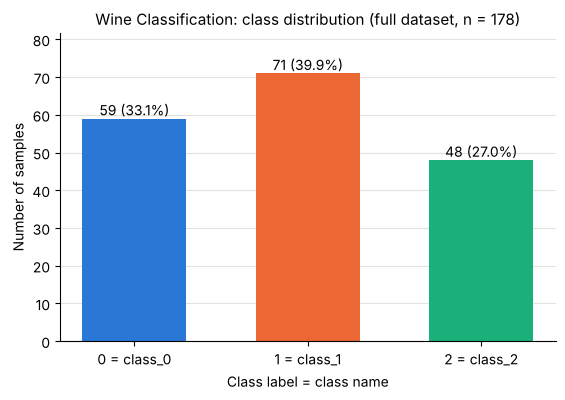

Saved figure: figures/wine_class_distribution.png


In [10]:
# Figure: class distribution
fig, ax = plt.subplots(figsize=(1.6 + 1.6 * len(CLASS_LABELS), 4))
counts = [int((y == c).sum()) for c in CLASS_LABELS]
tick_labels = [f"{c} = {n}" for c, n in zip(CLASS_LABELS, TARGET_NAMES)]
bars = ax.bar(tick_labels, counts, color=CLASS_COLORS[:len(CLASS_LABELS)], width=0.6)
for b, n in zip(bars, counts):
    ax.text(b.get_x() + b.get_width() / 2, n, f"{n} ({100 * n / len(y):.1f}%)",
            ha="center", va="bottom")
ax.set_xlabel("Class label = class name")
ax.set_ylabel("Number of samples")
ax.set_title(f"{DATASET_TITLE}: class distribution (full dataset, n = {len(y)})")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, max(counts) * 1.15)
save_fig(fig, "class_distribution")

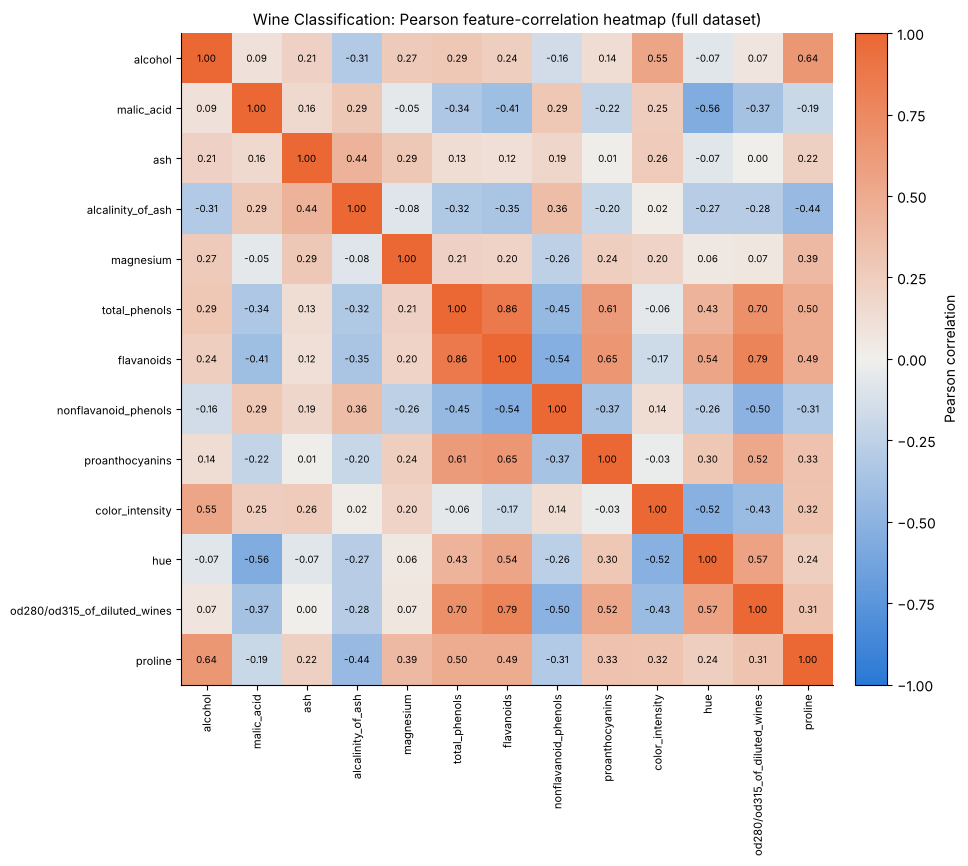

Saved figure: figures/wine_correlation_heatmap.png


In [11]:
# Figure: Pearson feature-correlation heatmap
corr = X.corr(method="pearson")
n_feat = corr.shape[0]
size = max(7, 0.42 * n_feat + 3)
fig, ax = plt.subplots(figsize=(size + 1, size))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(n_feat), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(n_feat), corr.index, fontsize=8)
ax.grid(False)
if n_feat <= 15:   # annotate only when the cells are large enough to read
    for i in range(n_feat):
        for j in range(n_feat):
            ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
cbar.set_label("Pearson correlation")
ax.set_title(f"{DATASET_TITLE}: Pearson feature-correlation heatmap (full dataset)")
save_fig(fig, "correlation_heatmap")

In [12]:
# Three strongest unique feature pairs by absolute correlation
# (upper triangle only -> the diagonal and the mirrored pairs are excluded)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().dropna().rename("pearson_r").reset_index()
pairs.columns = ["feature_1", "feature_2", "pearson_r"]
pairs["abs_r"] = pairs["pearson_r"].abs()
top3_pairs = pairs.sort_values("abs_r", ascending=False).head(3).reset_index(drop=True)
print(f"[{DATASET_TITLE}] Unique feature pairs checked: {len(pairs)}")
print("Three strongest unique pairs by |Pearson r|:")
display(top3_pairs)

[Wine Classification] Unique feature pairs checked: 78
Three strongest unique pairs by |Pearson r|:


,feature_1,feature_2,pearson_r,abs_r
0,total_phenols,flavanoids,0.8646,0.8646
1,flavanoids,od280/od315_of_diluted_wines,0.7872,0.7872
2,total_phenols,od280/od315_of_diluted_wines,0.6999,0.6999


**Class distribution.** 59, 71 and 48 samples in class_0, class_1 and class_2 (33.1%, 39.9% and 27.0%). The largest class is about 1.5 times the smallest, so the imbalance is mild.

**Three strongest unique feature pairs (|Pearson r|):**

| Rank | Pair | r |
|---|---|---|
| 1 | `total_phenols` – `flavanoids` | 0.8646 |
| 2 | `flavanoids` – `od280/od315_of_diluted_wines` | 0.7872 |
| 3 | `total_phenols` – `od280/od315_of_diluted_wines` | 0.6999 |

All three pairs are formed by the same three features, and all three correlations are positive: wines with more total phenols also have more flavanoids (flavanoids are one group of phenols) and a higher OD280/OD315 value. These features therefore carry partly the same information, which again conflicts with the independence assumption of Gaussian Naive Bayes and gives this property extra weight in distance-based methods. The correlations are clearly weaker than in the Breast Cancer dataset (strongest pair 0.86 here). As required, this is only described: no feature is removed and all model experiments use all 13 original features.

### 3.3 Boxplots

Each feature has its own panel and its own y-axis because the features have very different ranges. The features are grouped into several figures to keep them readable.

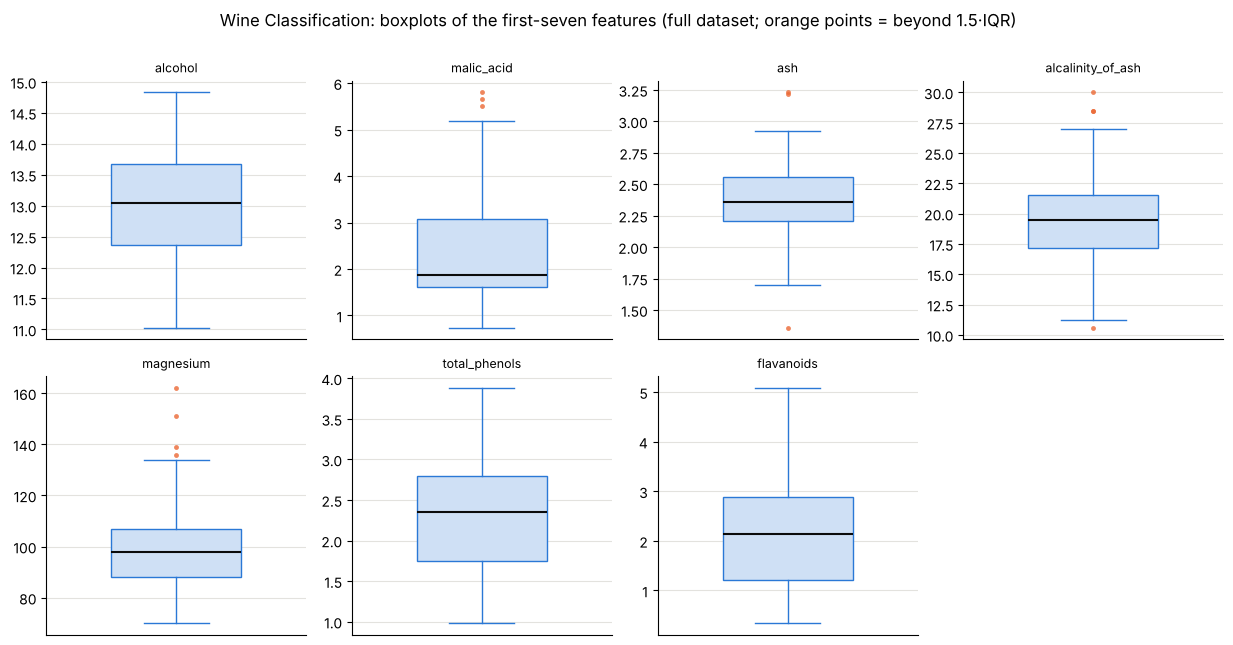

Saved figure: figures/wine_boxplots_first_seven.png


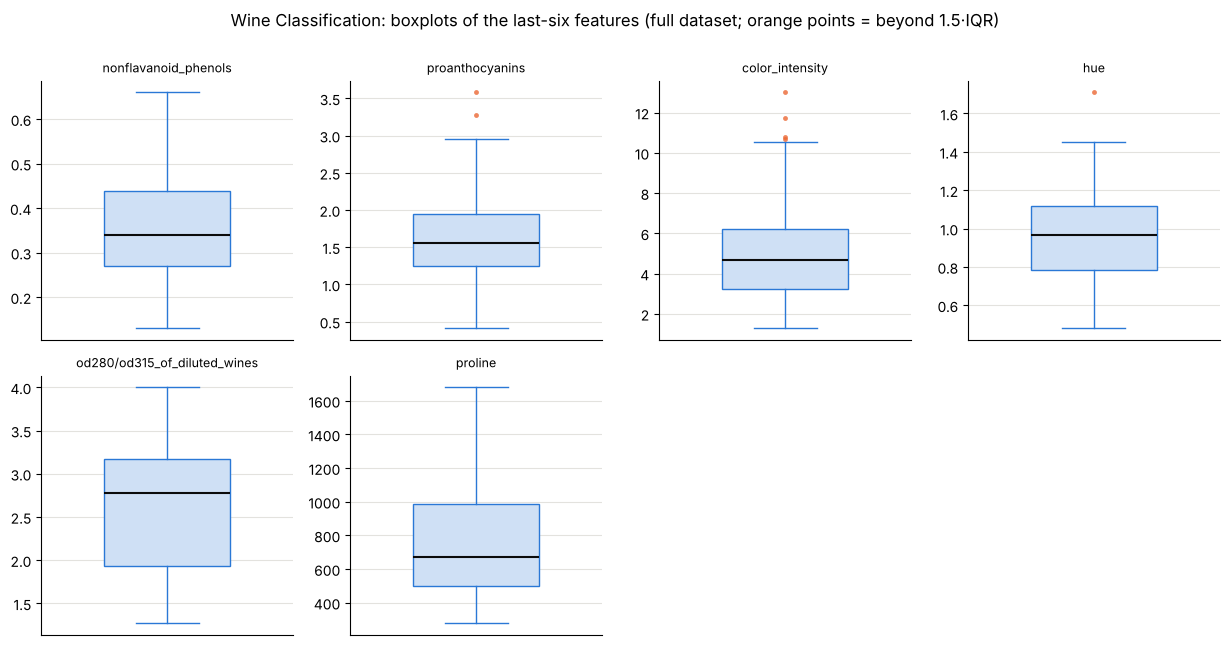

Saved figure: figures/wine_boxplots_last_six.png


In [13]:
BOXPLOT_GROUPS = {"first-seven features": (0, 7), "last-six features": (7, 13)}

for group_name, (start, stop) in BOXPLOT_GROUPS.items():
    feats = list(X.columns[start:stop])
    n_cols = 5 if len(feats) > 8 else 4
    n_rows = int(np.ceil(len(feats) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.1 * n_cols, 3.2 * n_rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, feat in zip(axes, feats):
        ax.boxplot(X[feat], widths=0.5, patch_artist=True,
                   boxprops=dict(facecolor="#cfe0f5", edgecolor="#2a78d6"),
                   medianprops=dict(color="#0b0b0b", linewidth=1.5),
                   whiskerprops=dict(color="#2a78d6"), capprops=dict(color="#2a78d6"),
                   flierprops=dict(marker="o", markersize=3.5, markerfacecolor="#eb6834",
                                   markeredgecolor="none", alpha=0.8))
        ax.set_title(feat, fontsize=9)
        ax.set_xticks([])
        ax.grid(axis="x", visible=False)
    for ax in axes[len(feats):]:
        ax.set_visible(False)
    fig.suptitle(f"{DATASET_TITLE}: boxplots of the {group_name} (full dataset; orange points = beyond 1.5·IQR)",
                 y=1.0)
    fig.tight_layout()
    save_fig(fig, f"boxplots_{group_name.split()[0].replace('-', '_').lower()}")

**Observations.**

1. **Feature ranges are very different.** `proline` ranges from 278 to 1680 and `magnesium` from 70 to 162, while `hue` lies between 0.48 and 1.71 and `nonflavanoid_phenols` between 0.13 and 0.66. Without scaling, `proline` would dominate any Euclidean distance.
2. **There are only a few outliers.** `magnesium` has 4 high values (maximum 162, median 98), `color_intensity` has 4 high values (maximum 13.0, median 4.69) and `malic_acid` has 3. `ash` and `alcalinity_of_ash` are the only features with flagged values on both sides.
3. **Six features have no point beyond the whiskers**, including `alcohol`, `flavanoids` and `proline`, so this dataset is much less affected by extreme values than Breast Cancer.

## 4. Splitting the Datasets

### 4.1 Fix the test set and repeat the training/validation split

* The 20% test set is reserved **once** with `test_size=0.20`, `stratify=y`, `random_state=42`. Its row indices never change.
* For each seed in `[42, 52, 62]` the remaining 80% is split into training and validation with `test_size=0.125`, stratified, `random_state=seed`. Because 0.125 × 0.80 = 0.10, this gives about 70% / 10% / 20%.
* `train_test_split` keeps the original pandas row indices, so every subset can be traced back to the original rows.

In [14]:
# 1) Reserve the fixed test set ONCE
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=TEST_SPLIT_SEED)

# 2) Repeat the training/validation split for each seed
splits = {}
for seed in SEEDS:
    X_tr, X_va, y_tr, y_va = train_test_split(
        X_trainval, y_trainval, test_size=0.125, stratify=y_trainval, random_state=seed)
    splits[seed] = {"X_train": X_tr, "X_val": X_va, "y_train": y_tr, "y_val": y_va}

print(f"[{DATASET_TITLE}] Fixed test set: X_test {X_test.shape}, y_test {y_test.shape}")
for seed in SEEDS:
    s = splits[seed]
    print(f"seed {seed}: X_train {s['X_train'].shape}, X_val {s['X_val'].shape}, "
          f"y_train {s['y_train'].shape}, y_val {s['y_val'].shape}")

[Wine Classification] Fixed test set: X_test (36, 13), y_test (36,)
seed 42: X_train (124, 13), X_val (18, 13), y_train (124,), y_val (18,)
seed 52: X_train (124, 13), X_val (18, 13), y_train (124,), y_val (18,)
seed 62: X_train (124, 13), X_val (18, 13), y_train (124,), y_val (18,)


### 4.2 Verify the split

In [15]:
def subset_row(seed, subset, y_part):
    row = {"dataset": DATASET_KEY, "seed": seed, "subset": subset,
           "n_samples": len(y_part),
           "percent_of_full": round(100 * len(y_part) / len(y), 2)}
    for c, name in zip(CLASS_LABELS, TARGET_NAMES):
        col = f"n_class_{c}" if name == f"class_{c}" else f"n_class_{c}_{name}"
        row[col] = int((y_part == c).sum())
    return row

split_rows = []
for seed in SEEDS:
    split_rows.append(subset_row(seed, "train", splits[seed]["y_train"]))
    split_rows.append(subset_row(seed, "validation", splits[seed]["y_val"]))
    split_rows.append(subset_row(seed, "test", y_test))
split_summary = pd.DataFrame(split_rows)
print(f"[{DATASET_TITLE}] Split summary: 3 subsets x 3 seeds = {len(split_summary)} rows")
display(split_summary)

[Wine Classification] Split summary: 3 subsets x 3 seeds = 9 rows


,dataset,seed,subset,n_samples,percent_of_full,n_class_0,n_class_1,n_class_2
0,wine,42,train,124,69.66,41,50,33
1,wine,42,validation,18,10.11,6,7,5
2,wine,42,test,36,20.22,12,14,10
3,wine,52,train,124,69.66,41,50,33
4,wine,52,validation,18,10.11,6,7,5
5,wine,52,test,36,20.22,12,14,10
6,wine,62,train,124,69.66,41,50,33
7,wine,62,validation,18,10.11,6,7,5
8,wine,62,test,36,20.22,12,14,10


In [16]:
# Overlap, completeness and fixed-test checks
check_rows = []
test_idx_reference = sorted(X_test.index)
for seed in SEEDS:
    tr = set(splits[seed]["X_train"].index)
    va = set(splits[seed]["X_val"].index)
    te = set(X_test.index)
    # labels must carry the same indices as the features
    assert list(splits[seed]["X_train"].index) == list(splits[seed]["y_train"].index)
    assert list(splits[seed]["X_val"].index) == list(splits[seed]["y_val"].index)
    # the rows that are neither training nor validation in this repetition:
    left_out = sorted(set(X.index) - tr - va)
    check_rows.append({
        "seed": seed,
        "train ∩ val": len(tr & va),
        "train ∩ test": len(tr & te),
        "val ∩ test": len(va & te),
        "train + val + test": len(tr) + len(va) + len(te),
        "full dataset": len(X),
        "covers all rows": (tr | va | te) == set(X.index),
        "test indices identical": left_out == test_idx_reference,
    })
split_checks = pd.DataFrame(check_rows)
print(f"[{DATASET_TITLE}] Split verification")
display(split_checks)

assert (split_checks[["train ∩ val", "train ∩ test", "val ∩ test"]] == 0).all().all()
assert (split_checks["train + val + test"] == len(X)).all()
assert split_checks["covers all rows"].all() and split_checks["test indices identical"].all()
print("No overlap inside any repetition, the counts sum to the complete dataset,")
print("and the test indices are identical across all three repetitions.")

[Wine Classification] Split verification


,seed,train ∩ val,train ∩ test,val ∩ test,train + val + test,full dataset,covers all rows,test indices identical
0,42,0,0,0,178,178,True,True
1,52,0,0,0,178,178,True,True
2,62,0,0,0,178,178,True,True


No overlap inside any repetition, the counts sum to the complete dataset,
and the test indices are identical across all three repetitions.


In [17]:
# Inspectable original row indices
index_rows = []
for seed in SEEDS:
    for subset, idx in [("train", splits[seed]["X_train"].index),
                        ("validation", splits[seed]["X_val"].index),
                        ("test", X_test.index)]:
        for i in sorted(idx):
            index_rows.append({"dataset": DATASET_KEY, "seed": seed, "subset": subset, "row_index": int(i)})
split_indices = pd.DataFrame(index_rows)
split_indices_path = RESULTS_DIR / f"{DATASET_KEY}_split_indices.csv"
split_indices.to_csv(split_indices_path, index=False)
print(f"All row indices saved to {split_indices_path.as_posix()} ({len(split_indices)} rows)")

compact = (split_indices.groupby(["seed", "subset"], sort=False)["row_index"]
           .agg(n="count", first_15_sorted_indices=lambda s: ", ".join(map(str, list(s)[:15])) + ", ...")
           .reset_index())
print(f"[{DATASET_TITLE}] Original row indices of every subset (first 15 shown; full lists below and in the CSV file)")
with pd.option_context("display.max_colwidth", None):
    display(compact)

print("Fixed test row indices (same for every seed):")
print(sorted(int(i) for i in X_test.index))
for seed in SEEDS:
    print(f"\nValidation row indices, seed {seed}:")
    print(sorted(int(i) for i in splits[seed]["X_val"].index))

All row indices saved to results/wine_split_indices.csv (534 rows)
[Wine Classification] Original row indices of every subset (first 15 shown; full lists below and in the CSV file)


,seed,subset,n,first_15_sorted_indices
0,42,train,124,"2, 3, 5, 8, 9, 11, 12, 13, 15, 16, 17, 19, 21, 23, 24, ..."
1,42,validation,18,"0, 1, 4, 6, 33, 35, 79, 86, 89, 97, 110, 120, 123, 145, 157, ..."
2,42,test,36,"7, 10, 14, 18, 20, 22, 28, 38, 42, 48, 51, 58, 60, 62, 64, ..."
3,52,train,124,"0, 1, 3, 4, 5, 6, 8, 9, 11, 12, 13, 15, 16, 17, 19, ..."
4,52,validation,18,"2, 31, 33, 34, 40, 45, 63, 69, 70, 91, 114, 116, 120, 138, 140, ..."
5,52,test,36,"7, 10, 14, 18, 20, 22, 28, 38, 42, 48, 51, 58, 60, 62, 64, ..."
6,62,train,124,"0, 1, 3, 4, 5, 6, 8, 11, 12, 13, 16, 17, 19, 21, 23, ..."
7,62,validation,18,"2, 9, 15, 25, 27, 29, 67, 68, 101, 107, 123, 124, 128, 146, 150, ..."
8,62,test,36,"7, 10, 14, 18, 20, 22, 28, 38, 42, 48, 51, 58, 60, 62, 64, ..."


Fixed test row indices (same for every seed):
[7, 10, 14, 18, 20, 22, 28, 38, 42, 48, 51, 58, 60, 62, 64, 66, 93, 94, 98, 100, 102, 105, 108, 112, 121, 129, 130, 132, 134, 143, 155, 164, 166, 173, 176, 177]

Validation row indices, seed 42:
[0, 1, 4, 6, 33, 35, 79, 86, 89, 97, 110, 120, 123, 145, 157, 158, 160, 169]

Validation row indices, seed 52:
[2, 31, 33, 34, 40, 45, 63, 69, 70, 91, 114, 116, 120, 138, 140, 146, 165, 171]

Validation row indices, seed 62:
[2, 9, 15, 25, 27, 29, 67, 68, 101, 107, 123, 124, 128, 146, 150, 151, 168, 175]


**Result.** Every repetition has 124 training rows (69.66%), 18 validation rows (10.11%) and 36 test rows (20.22%). Because every split is stratified, the class counts are the same for every seed: 41 / 50 / 33 in training, 6 / 7 / 5 in validation and 12 / 14 / 10 in the test set (class_0 / class_1 / class_2).

The checks confirm that inside each repetition the three subsets do not overlap, that their counts sum to 178, and that the test row indices are identical for all three seeds. The seeds only change which of the 142 non-test rows go to training and which go to validation. The three repetitions overlap with each other, so they are **not** three independent datasets and **not** a three-fold cross-validation.

The validation subsets are very small: with 18 samples, one prediction changes the accuracy by 5.6 percentage points. This must be kept in mind when the validation results are compared.

All subsets are stored in `splits[seed]` and keep their original row indices. Every algorithm, parameter value and representation of a given seed reads the same subsets from this dictionary.

## 5. Data Preprocessing and Scaling

### 5.1 Handle missing values, if present

In [18]:
missing_per_subset = pd.DataFrame([
    {"seed": seed,
     "missing in X_train": int(splits[seed]["X_train"].isna().sum().sum()),
     "missing in X_val": int(splits[seed]["X_val"].isna().sum().sum()),
     "missing in X_test": int(X_test.isna().sum().sum())}
    for seed in SEEDS])
print(f"[{DATASET_TITLE}] Missing values in the training, validation and test subsets, per seed")
display(missing_per_subset)

NEEDS_IMPUTATION = bool(missing_per_subset.drop(columns="seed").to_numpy().sum() > 0)
print("Imputation needed:", NEEDS_IMPUTATION)
if not NEEDS_IMPUTATION:
    print("=> No missing values exist in any subset, so no imputation step is added.")

[Wine Classification] Missing values in the training, validation and test subsets, per seed


,seed,missing in X_train,missing in X_val,missing in X_test
0,42,0,0,0
1,52,0,0,0
2,62,0,0,0


Imputation needed: False
=> No missing values exist in any subset, so no imputation step is added.


No missing values exist in the training, validation or test subsets, so no imputer is fitted and no imputation step is added.

### 5.2 Select one scaler

**Selected scaler: `StandardScaler`** (chosen before running any experiment, and used for both datasets and all three seeds).

`StandardScaler` subtracts the training mean of each feature and divides by its training standard deviation, so every feature has mean 0 and standard deviation 1 on the training subset. It was selected because KNN and K-Means use Euclidean distances, and the features of this dataset are measured on very different scales (see Section 3.1). After standardisation each feature contributes to the distance on a comparable scale.

### 5.3 Fit and apply the scaler correctly

A **new** scaler is created for each seed and fitted **only on that seed's training features**. The same fitted scaler then transforms the matching training and validation subsets. The test set is transformed only with the scaler fitted under seed 42. The target labels are never scaled.

In [19]:
def to_frame(array, like):
    """Put a transformed array back into a DataFrame with the same row index and columns."""
    return pd.DataFrame(array, index=like.index, columns=like.columns)

scalers = {}
X_train_scaled = {}
X_val_scaled = {}
for seed in SEEDS:
    scaler = StandardScaler()                         # new instance for this dataset/seed
    scaler.fit(splits[seed]["X_train"])               # fitted on training features ONLY
    scalers[seed] = scaler
    X_train_scaled[seed] = to_frame(scaler.transform(splits[seed]["X_train"]), splits[seed]["X_train"])
    X_val_scaled[seed] = to_frame(scaler.transform(splits[seed]["X_val"]), splits[seed]["X_val"])

# Final testing uses ONLY the scaler fitted under seed 42
X_test_scaled = to_frame(scalers[FINAL_SEED].transform(X_test), X_test)

scaler_check = pd.DataFrame([
    {"seed": seed,
     "scaler fitted on n rows": int(scalers[seed].n_samples_seen_),
     "n training rows": len(splits[seed]["X_train"]),
     "train mean (avg over features)": X_train_scaled[seed].mean().mean(),
     "train std (avg over features)": X_train_scaled[seed].std(ddof=0).mean(),
     "val mean (avg over features)": X_val_scaled[seed].mean().mean(),
     "val std (avg over features)": X_val_scaled[seed].std(ddof=0).mean()}
    for seed in SEEDS])
print(f"[{DATASET_TITLE}] One fitted StandardScaler per seed ({len(scalers)} for this dataset)")
display(scaler_check)

[Wine Classification] One fitted StandardScaler per seed (3 for this dataset)


,seed,scaler fitted on n rows,n training rows,train mean (avg over features),train std (avg over features),val mean (avg over features),val std (avg over features)
0,42,124,124,-3.7439e-16,1.0,0.1504,1.0262
1,52,124,124,-2.9092e-16,1.0,-0.0349,1.0008
2,62,124,124,-1.2025e-16,1.0,-0.0049,1.0228


In [20]:
# Before/after comparison for seed 42 only
print(f"[{DATASET_TITLE}] Seed 42 – first five TRAINING rows BEFORE scaling")
display(splits[FINAL_SEED]["X_train"].head())
print(f"[{DATASET_TITLE}] Seed 42 – the same five TRAINING rows AFTER StandardScaler")
display(X_train_scaled[FINAL_SEED].head())

range_compare = pd.DataFrame({
    "min before": splits[FINAL_SEED]["X_train"].min(),
    "max before": splits[FINAL_SEED]["X_train"].max(),
    "min after": X_train_scaled[FINAL_SEED].min(),
    "max after": X_train_scaled[FINAL_SEED].max(),
})
print(f"[{DATASET_TITLE}] Seed 42 – training feature ranges before and after scaling")
display(range_compare)

[Wine Classification] Seed 42 – first five TRAINING rows BEFORE scaling


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0


[Wine Classification] Seed 42 – the same five TRAINING rows AFTER StandardScaler


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.0175,1.0892,-0.0401,-0.3084,0.4332,-1.3425,-1.3223,0.3527,-1.1176,0.1258,-1.2268,-1.2236,-0.2094
148,0.4397,0.8918,0.0729,0.6094,-0.5057,-0.4910,-1.2599,0.7699,-0.5719,1.5123,-1.8114,-1.4147,-0.2914
116,-1.4654,-0.7720,-1.3968,0.3953,-0.9081,-0.4121,-0.3865,-0.4819,-0.0789,-1.3445,-0.0125,1.0978,-0.8000
122,-0.7033,2.0104,1.3920,2.1391,0.1650,-0.0652,0.1645,0.6030,0.2380,-1.2871,-0.1475,0.7893,-1.2265
115,-2.4687,-0.7344,-0.6054,0.6094,-0.9752,0.3448,0.2061,1.3541,0.7661,-1.3665,3.4052,0.4219,-1.0887


[Wine Classification] Seed 42 – training feature ranges before and after scaling


,min before,max before,min after,max after
alcohol,11.03,14.83,-2.4687,2.3575
malic_acid,0.74,5.51,-1.4582,3.0256
ash,1.36,3.22,-3.7710,3.2386
alcalinity_of_ash,10.60,30.00,-2.7253,3.2099
magnesium,78.00,162.00,-1.4446,4.1889
total_phenols,0.98,3.88,-1.9890,2.5839
flavanoids,0.34,3.74,-1.6966,1.8384
nonflavanoid_phenols,0.13,0.63,-1.9006,2.2721
proanthocyanins,0.42,3.28,-2.0331,3.0019
color_intensity,1.28,11.75,-1.6403,2.9826


**How the values changed (seed 42).** Before scaling, the five training rows are in their original units: `proline` is in the hundreds (365 to 675), `magnesium` around 85–106, and features such as `hue` or `nonflavanoid_phenols` are below 2. After `StandardScaler`, every feature is expressed as "number of training standard deviations from the training mean". For example, the `proline` values 675, 650, 495, 365 and 407 become −0.21, −0.29, −0.80, −1.23 and −1.09, and all columns are now on a comparable scale.

The range table shows that the scaled training features lie between about −3.8 (`ash`) and 4.2 (`magnesium`). The few outliers from Section 2.2 are still visible as the largest scaled values: scaling changes the units, it does not remove them.

**Leakage check.** On the training subsets the scaled features have mean 0 and standard deviation 1. On the validation subsets they do not (for seed 42 the average mean is 0.15 and the average standard deviation 1.03). This is expected and correct: the validation rows were only transformed with training statistics and were never used to fit a scaler. Three scalers are fitted for this dataset (one per seed), and the test set is transformed only with the seed-42 scaler.

## 6. Preparing the Two Data Representations

For each seed there are two representations with the **same features and the same row indices**:

* **unscaled** – all original features (no imputation was needed);
* **scaled** – the same features after the training-fitted `StandardScaler` of Section 5.

No feature selection and no dimensionality reduction is applied.

In [21]:
representations = {
    seed: {
        "unscaled": {"X_train": splits[seed]["X_train"], "X_val": splits[seed]["X_val"]},
        "scaled": {"X_train": X_train_scaled[seed], "X_val": X_val_scaled[seed]},
    }
    for seed in SEEDS
}
# Test features under the seed-42 preprocessing (used only in Sections 9 and 10.2)
test_representations = {"unscaled": X_test, "scaled": X_test_scaled}

rep_rows = []
for seed in SEEDS:
    u, s = representations[seed]["unscaled"], representations[seed]["scaled"]
    rep_rows.append({
        "seed": seed,
        "n_features unscaled": u["X_train"].shape[1],
        "n_features scaled": s["X_train"].shape[1],
        "same training indices": list(u["X_train"].index) == list(s["X_train"].index),
        "same validation indices": list(u["X_val"].index) == list(s["X_val"].index),
        "same feature names": list(u["X_train"].columns) == list(s["X_train"].columns),
    })
rep_check = pd.DataFrame(rep_rows)
print(f"[{DATASET_TITLE}] Check of the two representations (same features and same row indices), per seed")
display(rep_check)
assert rep_check.drop(columns=["seed", "n_features unscaled", "n_features scaled"]).all().all()
assert list(X_test.index) == list(X_test_scaled.index)

[Wine Classification] Check of the two representations (same features and same row indices), per seed


,seed,n_features unscaled,n_features scaled,same training indices,same validation indices,same feature names
0,42,13,13,True,True,True
1,52,13,13,True,True,True
2,62,13,13,True,True,True


## 7. Training the Classification Models

### 7.1 Required experiments

| Algorithm | Required settings | Fits for this dataset |
|---|---|---|
| Decision Tree | `max_depth` = 2, 3, 5, 10, None; `random_state = seed` | 5 × 2 × 3 = 30 |
| KNN | `n_neighbors` = 1, 3, 5, 7, 11; uniform weights; Euclidean distance | 5 × 2 × 3 = 30 |
| Gaussian Naive Bayes | `GaussianNB` with default settings | 1 × 2 × 3 = 6 |

Every model is fitted **on training data only**. All unspecified settings stay at their scikit-learn defaults. The grid is fixed; there is no extra parameter search.

In [22]:
# The prescribed grid: algorithm -> (parameter name, values)
CLASSIFIER_GRID = {
    "tree": ("max_depth", [2, 3, 5, 10, None]),
    "knn": ("n_neighbors", [1, 3, 5, 7, 11]),
    "gnb": (None, [None]),
}
ALGORITHM_NAMES = {"tree": "Decision Tree", "knn": "KNN", "gnb": "Gaussian NB"}

def make_classifier(algorithm, value, seed):
    """Create an unfitted classifier for one grid setting."""
    if algorithm == "tree":
        return DecisionTreeClassifier(max_depth=value, random_state=seed)
    if algorithm == "knn":   # KNN has no random_state
        return KNeighborsClassifier(n_neighbors=value, weights="uniform", metric="euclidean")
    if algorithm == "gnb":   # GaussianNB has no random_state
        return GaussianNB()
    raise ValueError(algorithm)

def param_tag(algorithm, value):
    """Short text used inside experiment IDs."""
    return {"tree": f"depth{value}", "knn": f"k{value}", "gnb": "default"}[algorithm]

def param_text(algorithm, value):
    """Readable parameter setting for the tables."""
    name = CLASSIFIER_GRID[algorithm][0]
    return "default" if name is None else f"{name}={value}"

def config_id(algorithm, representation, value):
    return f"{DATASET_KEY}_{algorithm}_{representation}_{param_tag(algorithm, value)}"

In [23]:
# Fit all 66 classifiers of this dataset: 11 settings x 2 representations x 3 seeds
fitted_models = {}      # run_id -> fitted model (kept in memory; the seed-42 ones are used in Section 9)
run_records = []        # one dictionary per run

for seed in SEEDS:
    y_tr = splits[seed]["y_train"]
    for representation in REPRESENTATIONS:
        X_tr = representations[seed][representation]["X_train"]
        for algorithm, (param_name, values) in CLASSIFIER_GRID.items():
            for value in values:
                cfg = config_id(algorithm, representation, value)
                run_id = f"{cfg}_s{seed}"
                model = make_classifier(algorithm, value, seed)
                model.fit(X_tr, y_tr)                       # training data only
                fitted_models[run_id] = model
                run_records.append({
                    "dataset": DATASET_KEY, "run_id": run_id, "config_id": cfg, "seed": seed,
                    "algorithm": ALGORITHM_NAMES[algorithm], "representation": representation,
                    "parameter": param_text(algorithm, value),
                })

print(f"[{DATASET_TITLE}] Classifier fits completed: {len(run_records)}")
assert len(run_records) == 66 and len(fitted_models) == 66
print("Example experiment IDs:")
for r in run_records[:3] + run_records[-2:]:
    print("  ", r["run_id"])

[Wine Classification] Classifier fits completed: 66
Example experiment IDs:
   wine_tree_unscaled_depth2_s42
   wine_tree_unscaled_depth3_s42
   wine_tree_unscaled_depth5_s42
   wine_knn_scaled_k11_s62
   wine_gnb_scaled_default_s62


### 7.2 Record and compare the experiments

Every run gets an experiment ID of the form `dataset_algorithm_representation_parameter_sSEED`, e.g. `wine_knn_scaled_k5_s42`. All runs are recorded, including the low-scoring ones. The seed is part of the run ID; it is **not** a parameter to optimise.

The metric functions below follow the conventions of Section 8.1 and are used for training, validation and (later) test data, so the conventions are always the same.

In [24]:
def roc_auc_from_proba(y_true, proba, classes):
    """Macro one-versus-rest ROC-AUC from the class-probability predictions.

    The probability columns follow model.classes_; the assert checks that this order
    matches the class labels [0, 1, 2]. Hard class predictions are never used here."""
    assert list(classes) == CLASS_LABELS, "probability-column order must match the class labels"
    return roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=list(classes))

def undefined_metric_classes(y_true, y_pred, classes):
    """List the classes whose precision or recall is undefined (zero denominator),
    BEFORE zero_division=0 replaces them."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    notes = []
    for c in classes:
        if (y_pred == c).sum() == 0:
            notes.append(f"precision undefined for class {c} (never predicted)")
        if (y_true == c).sum() == 0:
            notes.append(f"recall undefined for class {c} (no true samples)")
    return "; ".join(notes) if notes else "all defined"

def classifier_metrics(model, X_part, y_part):
    """The five metrics of Section 8.1 for one fitted model on one subset."""
    y_pred = model.predict(X_part)
    proba = model.predict_proba(X_part)
    return {
        "accuracy": accuracy_score(y_part, y_pred),
        "macro_precision": precision_score(y_part, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_part, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_part, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_from_proba(y_part, proba, model.classes_),
        "undefined": undefined_metric_classes(y_part, y_pred, model.classes_),
    }

In [25]:
# Training metrics for every run (accuracy and macro-F1)
for rec in run_records:
    model = fitted_models[rec["run_id"]]
    X_tr = representations[rec["seed"]][rec["representation"]]["X_train"]
    y_tr = splits[rec["seed"]]["y_train"]
    m = classifier_metrics(model, X_tr, y_tr)
    rec["train_accuracy"] = m["accuracy"]
    rec["train_macro_f1"] = m["macro_f1"]

print(f"[{DATASET_TITLE}] Training metrics recorded for {len(run_records)} runs "
      "(validation metrics are added in Section 8).")
display(pd.DataFrame(run_records).head(11))

[Wine Classification] Training metrics recorded for 66 runs (validation metrics are added in Section 8).


,dataset,run_id,config_id,seed,algorithm,representation,parameter,train_accuracy,train_macro_f1
0,wine,wine_tree_unscaled_depth2_s42,wine_tree_unscaled_depth2,42,Decision Tree,unscaled,max_depth=2,0.9355,0.9297
1,wine,wine_tree_unscaled_depth3_s42,wine_tree_unscaled_depth3,42,Decision Tree,unscaled,max_depth=3,0.9919,0.9926
2,wine,wine_tree_unscaled_depth5_s42,wine_tree_unscaled_depth5,42,Decision Tree,unscaled,max_depth=5,1.0000,1.0000
3,wine,wine_tree_unscaled_depth10_s42,wine_tree_unscaled_depth10,42,Decision Tree,unscaled,max_depth=10,1.0000,1.0000
4,wine,wine_tree_unscaled_depthNone_s42,wine_tree_unscaled_depthNone,42,Decision Tree,unscaled,max_depth=None,1.0000,1.0000
5,wine,wine_knn_unscaled_k1_s42,wine_knn_unscaled_k1,42,KNN,unscaled,n_neighbors=1,1.0000,1.0000
6,wine,wine_knn_unscaled_k3_s42,wine_knn_unscaled_k3,42,KNN,unscaled,n_neighbors=3,0.8468,0.8415
7,wine,wine_knn_unscaled_k5_s42,wine_knn_unscaled_k5,42,KNN,unscaled,n_neighbors=5,0.7984,0.7837
8,wine,wine_knn_unscaled_k7_s42,wine_knn_unscaled_k7,42,KNN,unscaled,n_neighbors=7,0.8145,0.8071
9,wine,wine_knn_unscaled_k11_s42,wine_knn_unscaled_k11,42,KNN,unscaled,n_neighbors=11,0.7500,0.7405


## 8. Measuring Validation Performance

### 8.1 Required metrics

For every classifier run the following are calculated on **its own validation subset**: accuracy, macro-precision, macro-recall, macro-F1 and ROC-AUC.

* Precision, recall and F1 use `average="macro"` and `zero_division=0`. Classes with an undefined precision or recall are identified *before* this replacement and stored in the column `undefined_metrics`.
* **ROC-AUC (Wine):** class-probability predictions with `multi_class="ovr"` and `average="macro"`. The code asserts that the probability-column order (`model.classes_`) equals the class labels `[0, 1, 2]`. Hard predictions are not used.

In [26]:
for rec in run_records:
    model = fitted_models[rec["run_id"]]
    X_va = representations[rec["seed"]][rec["representation"]]["X_val"]
    y_va = splits[rec["seed"]]["y_val"]
    m = classifier_metrics(model, X_va, y_va)
    rec["val_accuracy"] = m["accuracy"]
    rec["val_macro_precision"] = m["macro_precision"]
    rec["val_macro_recall"] = m["macro_recall"]
    rec["val_macro_f1"] = m["macro_f1"]
    rec["val_roc_auc"] = m["roc_auc"]
    rec["undefined_metrics"] = m["undefined"]

runs_df = pd.DataFrame(run_records)
n_undefined = int((runs_df["undefined_metrics"] != "all defined").sum())
print(f"Validation runs with an undefined class precision/recall: {n_undefined} of {len(runs_df)}")
if n_undefined == 0:
    print("=> Every class was predicted at least once and is present in every validation subset,")
    print("   so zero_division=0 never had to replace anything.")
else:
    display(runs_df.loc[runs_df["undefined_metrics"] != "all defined", ["run_id", "undefined_metrics"]])

Validation runs with an undefined class precision/recall: 0 of 66
=> Every class was predicted at least once and is present in every validation subset,
   so zero_division=0 never had to replace anything.


### 8.2 Comparison tables and model selection

**Run-level validation table (66 rows = 22 configurations × 3 seeds)**

In [27]:
METRIC_COLS = ["train_accuracy", "train_macro_f1", "val_accuracy", "val_macro_precision",
               "val_macro_recall", "val_macro_f1", "val_roc_auc"]
print(f"[{DATASET_TITLE}] Run-level table: {len(runs_df)} classifier runs (training + validation metrics)")
assert len(runs_df) == 66 and runs_df["run_id"].is_unique
display(runs_df[["run_id", "seed", "algorithm", "representation", "parameter"] + METRIC_COLS])

[Wine Classification] Run-level table: 66 classifier runs (training + validation metrics)


,run_id,seed,algorithm,representation,parameter,train_accuracy,train_macro_f1,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_roc_auc
0,wine_tree_unscaled_depth2_s42,42,Decision Tree,unscaled,max_depth=2,0.9355,0.9297,0.8333,0.8631,0.8111,0.8175,0.9106
1,wine_tree_unscaled_depth3_s42,42,Decision Tree,unscaled,max_depth=3,0.9919,0.9926,0.9444,0.9583,0.9444,0.9475,0.9686
2,wine_tree_unscaled_depth5_s42,42,Decision Tree,unscaled,max_depth=5,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571
3,wine_tree_unscaled_depth10_s42,42,Decision Tree,unscaled,max_depth=10,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571
4,wine_tree_unscaled_depthNone_s42,42,Decision Tree,unscaled,max_depth=None,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571
5,wine_knn_unscaled_k1_s42,42,KNN,unscaled,n_neighbors=1,1.0000,1.0000,0.6667,0.6750,0.6603,0.6646,0.7452
6,wine_knn_unscaled_k3_s42,42,KNN,unscaled,n_neighbors=3,0.8468,0.8415,0.6111,0.6111,0.6016,0.6041,0.8003
7,wine_knn_unscaled_k5_s42,42,KNN,unscaled,n_neighbors=5,0.7984,0.7837,0.7222,0.7159,0.7159,0.7128,0.8759
8,wine_knn_unscaled_k7_s42,42,KNN,unscaled,n_neighbors=7,0.8145,0.8071,0.6667,0.6714,0.6683,0.6605,0.8405
9,wine_knn_unscaled_k11_s42,42,KNN,unscaled,n_neighbors=11,0.7500,0.7405,0.6111,0.6159,0.6016,0.5998,0.8198


**Summary table (22 rows): mean and sample standard deviation (ddof = 1) across the three seeds**

The selection rule is applied in this order:
1. highest mean validation macro-F1;
2. tie → higher mean validation accuracy;
3. tie → lower standard deviation of validation macro-F1;
4. tie → alphabetical configuration ID.

Only validation results are used. The test set and the best single seed play no role in the selection.

In [28]:
group_cols = ["dataset", "config_id", "algorithm", "representation", "parameter"]
summary = runs_df.groupby(group_cols, sort=False)[METRIC_COLS].agg(["mean", "std"])   # pandas std: ddof=1
summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
summary = summary.reset_index()
summary.insert(5, "n_seeds", runs_df.groupby(group_cols, sort=False)["seed"].count().values)

# check that the standard deviation really is the sample standard deviation (ddof=1)
_first = runs_df[runs_df["config_id"] == summary.loc[0, "config_id"]]["val_macro_f1"]
assert np.isclose(summary.loc[0, "val_macro_f1_std"], np.std(_first, ddof=1))

# ranking with the tie-break rule (values rounded to 12 decimals to avoid floating-point noise)
rank_table = summary.assign(
    _f1=summary["val_macro_f1_mean"].round(12),
    _acc=summary["val_accuracy_mean"].round(12),
    _std=summary["val_macro_f1_std"].round(12),
).sort_values(["_f1", "_acc", "_std", "config_id"], ascending=[False, False, True, True])
rank_of = {cfg: i + 1 for i, cfg in enumerate(rank_table["config_id"])}
summary["selection_rank"] = summary["config_id"].map(rank_of)
SELECTED_CONFIG = rank_table.iloc[0]["config_id"]
summary["selected"] = summary["config_id"] == SELECTED_CONFIG

print(f"[{DATASET_TITLE}] Summary table: {len(summary)} configurations (mean and std over 3 seeds)")
assert len(summary) == 22
display(summary.drop(columns=["dataset"]))

[Wine Classification] Summary table: 22 configurations (mean and std over 3 seeds)


,config_id,algorithm,representation,parameter,n_seeds,train_accuracy_mean,train_accuracy_std,train_macro_f1_mean,train_macro_f1_std,val_accuracy_mean,val_accuracy_std,val_macro_precision_mean,val_macro_precision_std,val_macro_recall_mean,val_macro_recall_std,val_macro_f1_mean,val_macro_f1_std,val_roc_auc_mean,val_roc_auc_std,selection_rank,selected
0,wine_tree_unscaled_depth2,Decision Tree,unscaled,max_depth=2,3,0.9355,0.0081,0.9365,0.0106,0.8519,0.0321,0.8724,0.0214,0.8487,0.0495,0.8481,0.0365,0.9050,0.0219,17,False
1,wine_tree_unscaled_depth3,Decision Tree,unscaled,max_depth=3,3,0.9919,0.0000,0.9926,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9611,0.0431,12,False
2,wine_tree_unscaled_depth5,Decision Tree,unscaled,max_depth=5,3,1.0000,0.0000,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457,13,False
3,wine_tree_unscaled_depth10,Decision Tree,unscaled,max_depth=10,3,1.0000,0.0000,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457,11,False
4,wine_tree_unscaled_depthNone,Decision Tree,unscaled,max_depth=None,3,1.0000,0.0000,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457,14,False
5,wine_knn_unscaled_k1,KNN,unscaled,n_neighbors=1,3,1.0000,0.0000,1.0000,0.0000,0.7037,0.0321,0.6886,0.0239,0.6836,0.0223,0.6714,0.0226,0.7654,0.0181,18,False
6,wine_knn_unscaled_k3,KNN,unscaled,n_neighbors=3,3,0.8360,0.0123,0.8294,0.0134,0.6667,0.0556,0.6614,0.0496,0.6519,0.0478,0.6456,0.0429,0.8333,0.0311,20,False
7,wine_knn_unscaled_k5,KNN,unscaled,n_neighbors=5,3,0.7876,0.0093,0.7739,0.0091,0.7037,0.0321,0.7280,0.0722,0.6862,0.0294,0.6667,0.0399,0.8645,0.0115,19,False
8,wine_knn_unscaled_k7,KNN,unscaled,n_neighbors=7,3,0.7903,0.0213,0.7804,0.0231,0.6667,0.0000,0.6471,0.0225,0.6545,0.0153,0.6356,0.0316,0.8459,0.0084,21,False
9,wine_knn_unscaled_k11,KNN,unscaled,n_neighbors=11,3,0.7392,0.0093,0.7309,0.0083,0.6296,0.0321,0.6148,0.0127,0.6138,0.0211,0.6005,0.0010,0.8216,0.0254,22,False


In [29]:
top = summary.sort_values("selection_rank").head(5)
print(f"[{DATASET_TITLE}] Top 5 configurations by the selection rule (validation only)")
display(top[["selection_rank", "config_id", "val_macro_f1_mean", "val_macro_f1_std",
             "val_accuracy_mean", "val_roc_auc_mean", "train_macro_f1_mean"]])

selected_row = summary[summary["selected"]].iloc[0]
print("SELECTED CONFIGURATION:", SELECTED_CONFIG)
print(f"  mean validation macro-F1 = {selected_row['val_macro_f1_mean']:.4f} "
      f"(std = {selected_row['val_macro_f1_std']:.4f})")
print(f"  mean validation accuracy = {selected_row['val_accuracy_mean']:.4f}")
n_tied = int((summary["val_macro_f1_mean"].round(12) == round(selected_row["val_macro_f1_mean"], 12)).sum())
print(f"  configurations sharing the top mean validation macro-F1: {n_tied}"
      + ("  -> tie-break rule was needed" if n_tied > 1 else "  -> no tie"))

[Wine Classification] Top 5 configurations by the selection rule (validation only)


,selection_rank,config_id,val_macro_f1_mean,val_macro_f1_std,val_accuracy_mean,val_roc_auc_mean,train_macro_f1_mean
20,1,wine_knn_scaled_k11,0.9814,0.0323,0.9815,1.0000,0.9656
18,2,wine_knn_scaled_k5,0.9814,0.0323,0.9815,1.0000,0.9762
19,3,wine_knn_scaled_k7,0.9814,0.0323,0.9815,1.0000,0.9603
16,4,wine_knn_scaled_k1,0.9658,0.0296,0.9630,0.9749,1.0000
21,5,wine_gnb_scaled_default,0.9638,0.0314,0.9630,1.0000,0.9840


SELECTED CONFIGURATION: wine_knn_scaled_k11
  mean validation macro-F1 = 0.9814 (std = 0.0323)
  mean validation accuracy = 0.9815
  configurations sharing the top mean validation macro-F1: 3  -> tie-break rule was needed


In [30]:
# Supporting numbers for the discussion: scaling effect and training/validation gap
pivot = summary.pivot_table(index=["algorithm", "parameter"], columns="representation",
                            values="val_macro_f1_mean", sort=False)
pivot = pivot[["unscaled", "scaled"]]
pivot["scaled − unscaled"] = pivot["scaled"] - pivot["unscaled"]
print(f"[{DATASET_TITLE}] Mean validation macro-F1: unscaled vs scaled")
display(pivot)

# actual depth reached by the fitted trees (the same for both representations)
depth_rows = []
for value in CLASSIFIER_GRID["tree"][1]:
    row = {"max_depth setting": str(value)}
    for seed in SEEDS:
        row[f"actual depth, seed {seed}"] = fitted_models[f"{config_id('tree', 'unscaled', value)}_s{seed}"].get_depth()
    depth_rows.append(row)
print(f"[{DATASET_TITLE}] Depth actually reached by the fitted Decision Trees (unscaled runs)")
display(pd.DataFrame(depth_rows))

gap = summary[["config_id", "train_macro_f1_mean", "val_macro_f1_mean", "val_macro_f1_std"]].copy()
gap["train − val gap"] = gap["train_macro_f1_mean"] - gap["val_macro_f1_mean"]
print(f"[{DATASET_TITLE}] Training/validation macro-F1 gap and seed variability per configuration")
display(gap)

[Wine Classification] Mean validation macro-F1: unscaled vs scaled


representation                unscaled  scaled  scaled − unscaled
algorithm     parameter                                          
Decision Tree max_depth=2       0.8481  0.8481             0.0000
              max_depth=3       0.9462  0.9462             0.0000
              max_depth=5       0.9462  0.9462             0.0000
              max_depth=10      0.9462  0.9462             0.0000
              max_depth=None    0.9462  0.9462             0.0000
KNN           n_neighbors=1     0.6714  0.9658             0.2944
              n_neighbors=3     0.6456  0.9457             0.3002
              n_neighbors=5     0.6667  0.9814             0.3146
              n_neighbors=7     0.6356  0.9814             0.3458
              n_neighbors=11    0.6005  0.9814             0.3809
Gaussian NB   default           0.9638  0.9638             0.0000

[Wine Classification] Depth actually reached by the fitted Decision Trees (unscaled runs)


,max_depth setting,"actual depth, seed 42","actual depth, seed 52","actual depth, seed 62"
0,2,2,2,2
1,3,3,3,3
2,5,5,4,4
3,10,5,4,4
4,None,5,4,4


[Wine Classification] Training/validation macro-F1 gap and seed variability per configuration


,config_id,train_macro_f1_mean,val_macro_f1_mean,val_macro_f1_std,train − val gap
0,wine_tree_unscaled_depth2,0.9365,0.8481,0.0365,0.0883
1,wine_tree_unscaled_depth3,0.9926,0.9462,0.0545,0.0464
2,wine_tree_unscaled_depth5,1.0000,0.9462,0.0545,0.0538
3,wine_tree_unscaled_depth10,1.0000,0.9462,0.0545,0.0538
4,wine_tree_unscaled_depthNone,1.0000,0.9462,0.0545,0.0538
5,wine_knn_unscaled_k1,1.0000,0.6714,0.0226,0.3286
6,wine_knn_unscaled_k3,0.8294,0.6456,0.0429,0.1838
7,wine_knn_unscaled_k5,0.7739,0.6667,0.0399,0.1072
8,wine_knn_unscaled_k7,0.7804,0.6356,0.0316,0.1448
9,wine_knn_unscaled_k11,0.7309,0.6005,0.0010,0.1304


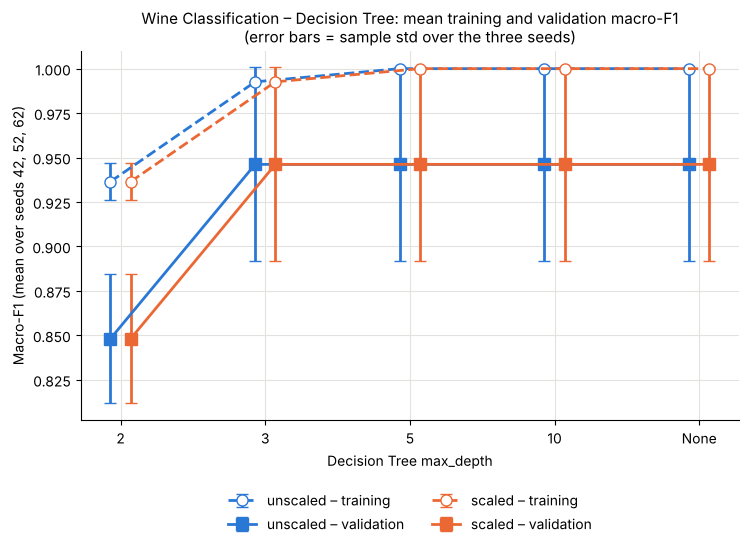

Saved figure: figures/wine_tree_depth_comparison.png


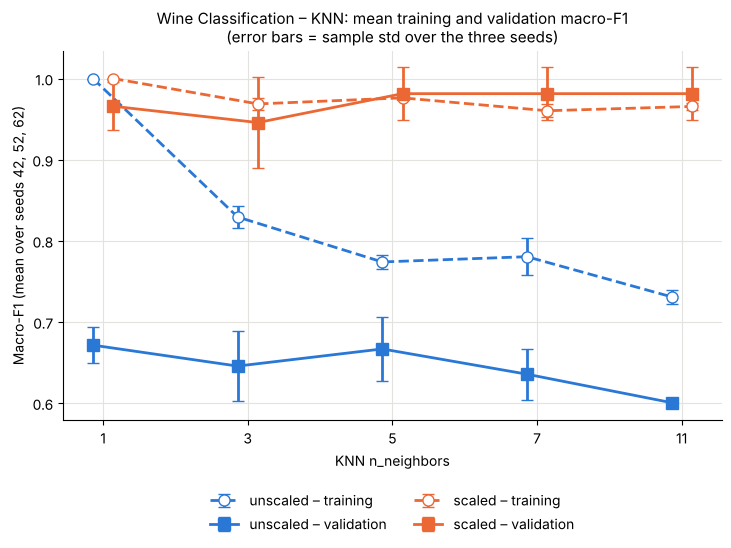

Saved figure: figures/wine_knn_neighbors_comparison.png


In [31]:
def plot_parameter_comparison(algorithm, xlabel, fig_name):
    """Mean training and validation macro-F1 against one parameter, both representations,
    with the standard deviation over the three seeds as error bars."""
    values = CLASSIFIER_GRID[algorithm][1]
    x = np.arange(len(values))
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    for representation, color, shift in zip(REPRESENTATIONS, CLASS_COLORS[:2], [-0.07, 0.07]):
        sub = (summary[(summary["algorithm"] == ALGORITHM_NAMES[algorithm])
                       & (summary["representation"] == representation)]
               .set_index("parameter").loc[[param_text(algorithm, v) for v in values]])
        ax.errorbar(x + shift, sub["train_macro_f1_mean"], yerr=sub["train_macro_f1_std"],
                    color=color, linestyle="--", linewidth=2, marker="o", markersize=8,
                    markerfacecolor="white", capsize=4, label=f"{representation} – training")
        ax.errorbar(x + shift, sub["val_macro_f1_mean"], yerr=sub["val_macro_f1_std"],
                    color=color, linestyle="-", linewidth=2, marker="s", markersize=8,
                    capsize=4, label=f"{representation} – validation")
    ax.set_xticks(x, [str(v) for v in values])
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Macro-F1 (mean over seeds 42, 52, 62)")
    ax.set_title(f"{DATASET_TITLE} – {ALGORITHM_NAMES[algorithm]}: mean training and validation macro-F1\n"
                 "(error bars = sample std over the three seeds)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
    save_fig(fig, fig_name)

plot_parameter_comparison("tree", "Decision Tree max_depth", "tree_depth_comparison")
plot_parameter_comparison("knn", "KNN n_neighbors", "knn_neighbors_comparison")

### Discussion of the validation results

**Selected configuration: `wine_knn_scaled_k11`** (KNN, scaled features, 11 neighbours) with mean validation macro-F1 = 0.9814 (std 0.0323) and mean validation accuracy = 0.9815.

**The tie-break rule was needed.** Three configurations — scaled KNN with k = 5, 7 and 11 — have exactly the same validation results in every seed (macro-F1 1.0000, 1.0000 and 0.9441). They are therefore tied on mean macro-F1 (rule 1), mean accuracy (rule 2) and standard deviation (rule 3). Rule 4, the alphabetical configuration ID, decides: `wine_knn_scaled_k11` comes before `wine_knn_scaled_k5` and `wine_knn_scaled_k7` in alphabetical (character-by-character) order. The data do not distinguish these three settings; k = 11 is selected only because the predeclared rule says so.

**Effect of scaling.**
* *Decision Tree:* scaled and unscaled results are exactly identical for every depth and every seed (difference 0.0000), because standardisation does not change the order of the values that a tree splits on.
* *Gaussian NB:* also identical (0.9638 in both representations). The model estimates a mean and a variance per feature and class, so a linear rescaling of a feature does not change its predictions here.
* *KNN:* the effect is very large. Unscaled mean validation macro-F1 is only 0.60–0.67, scaled it is 0.95–0.98: a gain of +0.29 to +0.38 (for example k = 11: 0.6005 → 0.9814). Without scaling the Euclidean distance is almost entirely determined by `proline`, whose standard deviation is about 315.

**Tree depth.** Depth 2 underfits: mean validation macro-F1 is 0.8481 (training 0.9365). Depth 3 reaches 0.9462 (training 0.9926). Depths 5, 10 and None give the same validation value of 0.9462 with training 1.0000, because the unrestricted trees stop at depth 4–5. So going deeper than 3 only raised the training score and did not improve validation.

**Neighbour count.** With scaled features the mean validation macro-F1 is 0.9658 (k = 1), 0.9457 (k = 3) and 0.9814 (k = 5, 7, 11): it drops at k = 3 before rising, so it is not monotonic. With unscaled features it tends to decrease with k (0.6714 at k = 1, 0.6005 at k = 11). Larger k did not always help.

**Training/validation gaps.** The largest gap belongs to unscaled KNN with k = 1 (training 1.0000, validation 0.6714, gap 0.329). For the selected configuration the validation mean (0.9814) is even slightly above the training mean (0.9656); with only 18 validation samples such a small negative gap is not surprising.

**Variability across seeds.** Standard deviations of validation macro-F1 go up to 0.056. For the selected configuration, seeds 42 and 52 are perfect and seed 62 has one error (17 of 18 correct). Over the three seeds, the selected configuration makes 1 error in 54 validation predictions, and Gaussian NB (0.9638) makes 2. The top configurations therefore differ by a single validation sample. The standard deviation only describes these three overlapping splits; it is not a confidence interval and not evidence of statistical significance.

## 9. Evaluating the Selected Models on the Test Sets

The selection is now frozen. Only the **seed-42 fitted instance** of the selected configuration is evaluated on the fixed test set, with the **seed-42 preprocessing**. The model is not refitted on training + validation, no other candidate is tested, and no seed is chosen by its score. This is a single final evaluation, not a new training run.

### 9.1 Final performance metrics

In [32]:
final_run_id = f"{SELECTED_CONFIG}_s{FINAL_SEED}"
final_model = fitted_models[final_run_id]                    # already fitted in Section 7
final_representation = selected_row["representation"]
X_test_final = test_representations[final_representation]    # seed-42 preprocessing

print("Selected configuration:", SELECTED_CONFIG)
print("Evaluated run (already fitted):", final_run_id)
print("Model:", final_model)
print("Test representation:", final_representation)

test_metrics = classifier_metrics(final_model, X_test_final, y_test)
y_test_pred = final_model.predict(X_test_final)
y_test_proba = final_model.predict_proba(X_test_final)
print("Undefined class precision/recall on the test set:", test_metrics["undefined"])

classifier_test = pd.DataFrame([{
    "dataset": DATASET_KEY,
    "selected_config": SELECTED_CONFIG,
    "evaluation_seed": FINAL_SEED,
    "val_macro_f1_mean": selected_row["val_macro_f1_mean"],
    "val_macro_f1_std": selected_row["val_macro_f1_std"],
    "test_accuracy": test_metrics["accuracy"],
    "test_macro_precision": test_metrics["macro_precision"],
    "test_macro_recall": test_metrics["macro_recall"],
    "test_macro_f1": test_metrics["macro_f1"],
    "test_roc_auc": test_metrics["roc_auc"],
}])
print(f"\n[{DATASET_TITLE}] Final test metrics (this dataset's row of the two-row final table)")
display(classifier_test)

Selected configuration: wine_knn_scaled_k11
Evaluated run (already fitted): wine_knn_scaled_k11_s42
Model: KNeighborsClassifier(metric='euclidean', n_neighbors=11)
Test representation: scaled
Undefined class precision/recall on the test set: all defined

[Wine Classification] Final test metrics (this dataset's row of the two-row final table)


,dataset,selected_config,evaluation_seed,val_macro_f1_mean,val_macro_f1_std,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc
0,wine,wine_knn_scaled_k11,42,0.9814,0.0323,1.0,1.0,1.0,1.0,1.0


In [33]:
print(f"[{DATASET_TITLE}] Classification report – TEST set – {final_run_id}\n")
print(classification_report(y_test, y_test_pred, labels=list(final_model.classes_),
                            target_names=TARGET_NAMES, digits=4, zero_division=0))
report_dict = classification_report(y_test, y_test_pred, labels=list(final_model.classes_),
                                    target_names=TARGET_NAMES, output_dict=True, zero_division=0)

[Wine Classification] Classification report – TEST set – wine_knn_scaled_k11_s42

              precision    recall  f1-score   support

     class_0     1.0000    1.0000    1.0000        12
     class_1     1.0000    1.0000    1.0000        14
     class_2     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36



In [34]:
# Validation (seed 42 and mean over seeds) next to the test result of the same configuration
val42 = runs_df[runs_df["run_id"] == final_run_id].iloc[0]
compare_rows = []
for metric in ["accuracy", "macro_precision", "macro_recall", "macro_f1", "roc_auc"]:
    compare_rows.append({
        "metric": metric,
        "validation mean (3 seeds)": selected_row[f"val_{metric}_mean"],
        "validation std (3 seeds)": selected_row[f"val_{metric}_std"],
        "validation (seed 42)": val42[f"val_{metric}"],
        "test (seed 42 model)": test_metrics[metric],
    })
val_vs_test = pd.DataFrame(compare_rows)
val_vs_test["test − validation mean"] = val_vs_test["test (seed 42 model)"] - val_vs_test["validation mean (3 seeds)"]
print(f"[{DATASET_TITLE}] Validation vs test for {SELECTED_CONFIG}")
display(val_vs_test)
print(f"Validation subset size: {len(splits[FINAL_SEED]['y_val'])} samples; test set size: {len(y_test)} samples")

[Wine Classification] Validation vs test for wine_knn_scaled_k11


,metric,validation mean (3 seeds),validation std (3 seeds),validation (seed 42),test (seed 42 model),test − validation mean
0,accuracy,0.9815,0.0321,1.0,1.0,0.0185
1,macro_precision,0.9815,0.0321,1.0,1.0,0.0185
2,macro_recall,0.9841,0.0275,1.0,1.0,0.0159
3,macro_f1,0.9814,0.0323,1.0,1.0,0.0186
4,roc_auc,1.0000,0.0000,1.0,1.0,0.0000


Validation subset size: 18 samples; test set size: 36 samples


**Validation versus test.** On the fixed test set the seed-42 model classifies all 36 samples correctly: accuracy, macro-precision, macro-recall, macro-F1 and ROC-AUC are all 1.0000. The mean validation macro-F1 of this configuration was 0.9814 (std 0.0323), and its seed-42 validation macro-F1 was also 1.0000. The test result is 0.0186 above the validation mean, which is less than one standard deviation and corresponds to the single validation error made under seed 62. Validation and test results are consistent. The selected model is **not** changed after seeing these results.

### 9.2 Confusion matrices

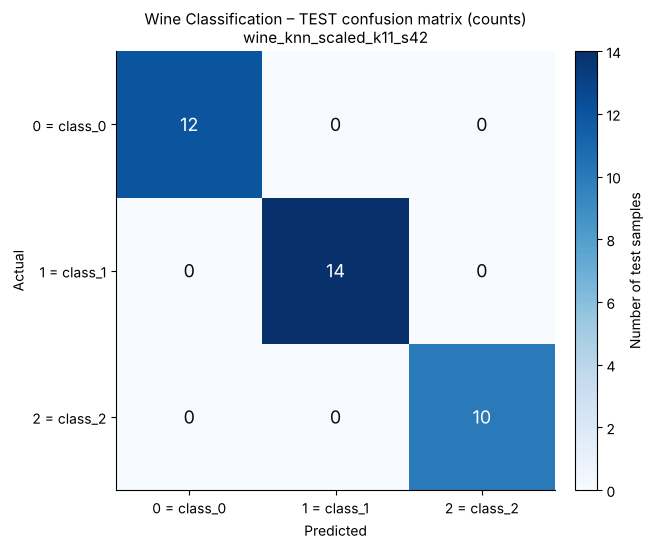

Saved figure: figures/wine_test_confusion_matrix.png
[Wine Classification] TEST confusion matrix as a table (counts) – wine_knn_scaled_k11_s42


,Predicted class_0,Predicted class_1,Predicted class_2
Actual class_0,12,0,0
Actual class_1,0,14,0
Actual class_2,0,0,10


In [35]:
cm_labels = list(final_model.classes_)                # class order [0, 1, 2]
cm = confusion_matrix(y_test, y_test_pred, labels=cm_labels)

fig, ax = plt.subplots(figsize=(1.9 + 1.5 * len(cm_labels), 1.5 + 1.4 * len(cm_labels)))
im = ax.imshow(cm, cmap="Blues", vmin=0)
tick_names = [f"{c} = {n}" for c, n in zip(cm_labels, TARGET_NAMES)]
ax.set_xticks(range(len(cm_labels)), tick_names)
ax.set_yticks(range(len(cm_labels)), tick_names)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.grid(False)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=13,
                color="white" if cm[i, j] > cm.max() / 2 else "#0b0b0b")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label("Number of test samples")
ax.set_title(f"{DATASET_TITLE} – TEST confusion matrix (counts)\n{final_run_id}")
save_fig(fig, "test_confusion_matrix")

cm_table = pd.DataFrame(cm, index=[f"Actual {n}" for n in TARGET_NAMES],
                        columns=[f"Predicted {n}" for n in TARGET_NAMES])
print(f"[{DATASET_TITLE}] TEST confusion matrix as a table (counts) – {final_run_id}")
display(cm_table)

In [36]:
# Largest off-diagonal confusion in the complete 3 x 3 matrix
off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)
print(f"Correct test predictions (diagonal): {int(np.trace(cm))} of {int(cm.sum())}")
print(f"Test errors (off-diagonal):          {int(off_diagonal.sum())}")
if off_diagonal.sum() == 0:
    print("=> There are no off-diagonal entries: the selected classifier makes no test errors.")
else:
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            if i != j and cm[i, j] > 0:
                print(f"  actual {TARGET_NAMES[i]} predicted as {TARGET_NAMES[j]}: {int(cm[i, j])}")
    i, j = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
    print(f"Largest off-diagonal cell: actual {TARGET_NAMES[i]} -> predicted {TARGET_NAMES[j]} "
          f"({int(cm[i, j])} sample(s))")

Correct test predictions (diagonal): 36 of 36
Test errors (off-diagonal):          0
=> There are no off-diagonal entries: the selected classifier makes no test errors.


In [37]:
def manual_class_metrics(cm, pos):
    """Precision, recall and F1 for one class (row/column position `pos`) versus all other classes,
    calculated by hand from the confusion-matrix counts."""
    tp = int(cm[pos, pos])
    fn = int(cm[pos, :].sum() - tp)
    fp = int(cm[:, pos].sum() - tp)
    tn = int(cm.sum() - tp - fn - fp)
    precision = tp / (tp + fp) if (tp + fp) > 0 else None     # None = undefined (zero denominator)
    recall = tp / (tp + fn) if (tp + fn) > 0 else None
    if precision is None or recall is None or (precision + recall) == 0:
        f1 = None
    else:
        f1 = 2 * precision * recall / (precision + recall)
    return tp, fp, fn, tn, precision, recall, f1

MANUAL_CLASS = 1                                   # class_1 versus all other classes
pos = cm_labels.index(MANUAL_CLASS)
class_name = TARGET_NAMES[pos]
tp, fp, fn, tn, p_manual, r_manual, f_manual = manual_class_metrics(cm, pos)

fmt = lambda v: "undefined (zero denominator)" if v is None else f"{v:.4f}"
print(f"[{DATASET_TITLE}] Manual check for class {MANUAL_CLASS} ({class_name}) versus all other classes")
print(f"  TP = {tp}, FP = {fp}, FN = {fn}, TN = {tn}")
print(f"  precision = TP / (TP + FP) = {tp} / ({tp} + {fp}) = {fmt(p_manual)}")
print(f"  recall    = TP / (TP + FN) = {tp} / ({tp} + {fn}) = {fmt(r_manual)}")
print(f"  F1        = 2 · precision · recall / (precision + recall) = {fmt(f_manual)}")

manual_check = pd.DataFrame({
    "metric": ["precision", "recall", "f1-score"],
    "manual (from confusion matrix)": [p_manual, r_manual, f_manual],
    f"classification report (class {class_name})": [report_dict[class_name]["precision"],
                                                    report_dict[class_name]["recall"],
                                                    report_dict[class_name]["f1-score"]],
})
manual_check["match"] = [
    (m is not None) and bool(np.isclose(m, r))
    for m, r in zip(manual_check.iloc[:, 1], manual_check.iloc[:, 2])]
display(manual_check)
print("Support of this class in the report:", int(report_dict[class_name]["support"]), "= TP + FN =", tp + fn)

[Wine Classification] Manual check for class 1 (class_1) versus all other classes
  TP = 14, FP = 0, FN = 0, TN = 22
  precision = TP / (TP + FP) = 14 / (14 + 0) = 1.0000
  recall    = TP / (TP + FN) = 14 / (14 + 0) = 1.0000
  F1        = 2 · precision · recall / (precision + recall) = 1.0000


,metric,manual (from confusion matrix),classification report (class class_1),match
0,precision,1.0,1.0,True
1,recall,1.0,1.0,True
2,f1-score,1.0,1.0,True


Support of this class in the report: 14 = TP + FN = 14


**Reading the confusion matrix.** The complete 3 × 3 matrix has 12, 14 and 10 on the diagonal and zeros everywhere else. **There are no off-diagonal entries, so there is no "largest confusion" to explain**: every class_0, class_1 and class_2 test wine was predicted correctly.

**Manual check (class_1 versus all other classes).** TP = 14 (class_1 predicted as class_1), FP = 0 (other classes predicted as class_1), FN = 0 (class_1 predicted as another class) and TN = 22. So precision = 14 / (14 + 0) = 1.0000, recall = 14 / (14 + 0) = 1.0000 and F1 = 1.0000. These values match the **class_1 row** of the classification report (the comparison is with the per-class values, not the macro averages). No denominator is zero, so no metric is undefined.

### 9.3 ROC curves

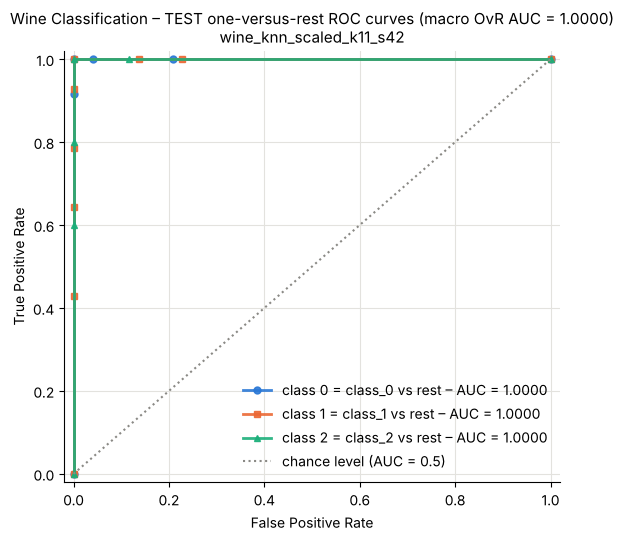

Saved figure: figures/wine_test_roc_curves.png
AUC class_0 vs rest: 1.0000
AUC class_1 vs rest: 1.0000
AUC class_2 vs rest: 1.0000
Macro one-versus-rest AUC: 1.0000


In [38]:
# One one-versus-rest ROC curve per class, all three in one figure
classes_ = list(final_model.classes_)
assert classes_ == CLASS_LABELS                                   # probability columns follow the class labels
y_test_bin = label_binarize(y_test, classes=classes_)             # one 0/1 column per class

fig, ax = plt.subplots(figsize=(6.4, 5.6))
class_auc = {}
for j, (c, name, color, marker) in enumerate(zip(classes_, TARGET_NAMES, CLASS_COLORS, CLASS_MARKERS)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, j], y_test_proba[:, j])
    class_auc[name] = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, linewidth=2, marker=marker, markersize=5, alpha=0.9,
            label=f"class {c} = {name} vs rest – AUC = {class_auc[name]:.4f}")
macro_ovr_auc = roc_auc_score(y_test, y_test_proba, multi_class="ovr", average="macro", labels=classes_)
assert np.isclose(macro_ovr_auc, test_metrics["roc_auc"])
assert np.isclose(macro_ovr_auc, np.mean(list(class_auc.values())))

ax.plot([0, 1], [0, 1], color="#8a8985", linestyle=":", linewidth=1.5, label="chance level (AUC = 0.5)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title(f"{DATASET_TITLE} – TEST one-versus-rest ROC curves (macro OvR AUC = {macro_ovr_auc:.4f})\n{final_run_id}")
ax.legend(loc="lower right", frameon=False)
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
save_fig(fig, "test_roc_curves")

for name, value in class_auc.items():
    print(f"AUC {name} vs rest: {value:.4f}")
print(f"Macro one-versus-rest AUC: {macro_ovr_auc:.4f}")

**Interpretation.** Each one-versus-rest curve goes straight from (0, 0) up to (0, 1) and then to (1, 1), and each class-specific AUC is 1.0000; the macro one-versus-rest AUC is also 1.0000. For every class, all test wines of that class received a higher predicted probability for it than any wine of the other classes.

**Effect of the decision threshold (in my own words).** For one class against the rest, a wine is assigned to the class when its predicted probability for that class is at least the threshold. If the threshold is lowered, more wines are assigned to the class: fewer true members are missed (fewer false negatives, higher TPR), but more wines of other classes are wrongly included (more false positives, higher FPR). If the threshold is raised, false positives decrease and false negatives increase. On this test set the classes are ranked perfectly, so there are thresholds with neither false positives nor false negatives; with harder data the curve would bend away from the top-left corner and a trade-off would be unavoidable.

This figure is descriptive only. No new threshold is chosen and nothing is tuned on the test set.

### 9.4 Error interpretation

In [39]:
errors = pd.DataFrame({
    "actual_label": y_test.values,
    "actual_name": [TARGET_NAMES[cm_labels.index(c)] for c in y_test.values],
    "predicted_label": y_test_pred,
    "predicted_name": [TARGET_NAMES[cm_labels.index(c)] for c in y_test_pred],
}, index=X_test.index)
for j, c in enumerate(cm_labels):
    errors[f"proba_class_{c}"] = y_test_proba[:, j]
errors.index.name = "original_row_index"
errors = errors[errors["actual_label"] != errors["predicted_label"]]

print(f"[{DATASET_TITLE}] Test misclassifications of {final_run_id}: {len(errors)} of {len(y_test)}")
if len(errors) == 0:
    print("=> The selected classifier makes NO errors on the test set.")
else:
    display(errors)

[Wine Classification] Test misclassifications of wine_knn_scaled_k11_s42: 0 of 36
=> The selected classifier makes NO errors on the test set.


In [40]:
# Closer look at one actual misclassification: the one with the most confident wrong prediction.
# Feature ranking and class means come from the seed-42 TRAINING data only.
X_tr42, y_tr42 = splits[FINAL_SEED]["X_train"], splits[FINAL_SEED]["y_train"]
f_values, _ = f_classif(X_tr42, y_tr42)
f_scores = pd.Series(f_values, index=X.columns).sort_values(ascending=False)

if len(errors) > 0:
    wrong_proba = errors.apply(lambda r: r[f"proba_class_{int(r['predicted_label'])}"], axis=1)
    error_idx = wrong_proba.idxmax()
    e = errors.loc[error_idx]
    print(f"Examined test sample: original row index {error_idx}")
    print(f"  actual class:    {int(e['actual_label'])} ({e['actual_name']})")
    print(f"  predicted class: {int(e['predicted_label'])} ({e['predicted_name']})")
    print("  predicted probabilities:",
          {f"class {c}": round(float(e[f'proba_class_{c}']), 4) for c in cm_labels})
    top_feats = list(f_scores.index[:6])
    detail = pd.DataFrame({
        "value of this sample": X_test.loc[error_idx, top_feats],
        f"training mean of actual class ({e['actual_name']})":
            X_tr42.loc[y_tr42 == e["actual_label"], top_feats].mean(),
        f"training mean of predicted class ({e['predicted_name']})":
            X_tr42.loc[y_tr42 == e["predicted_label"], top_feats].mean(),
    })
    print(f"\n[{DATASET_TITLE}] Test row {error_idx}: its values on the six features with the highest "
          "training ANOVA F-score, next to the seed-42 training class means")
    display(detail)
else:
    print("No misclassified test sample to examine.")

No misclassified test sample to examine.


**No test errors.** The selected classifier (`wine_knn_scaled_k11`, seed 42) makes no misclassification on the test set: 36 of 36 wines are correct, so there is no actual error to describe for this dataset.

**Why one error-free test result does not establish perfect generalisation.**
* The test set is small: 36 samples, only 10–14 per class. A classifier whose true accuracy is, for example, 95% would still get all 36 right with a probability of about 0.95³⁶ ≈ 16%. An error-free result on 36 samples is therefore compatible with a real error rate of several percent.
* The same configuration is not perfect elsewhere in this notebook: under seed 62 it made one validation error (17 of 18 correct).
* It is one split, one seed and one small dataset from one source, so the result says little about new wines.

**Limitations.** The validation subsets have only 18 samples, the three repetitions overlap because they are drawn from the same 142 rows, and only the predeclared seed-42 instance was tested once. The three validation repetitions are not repeated independent test results, and no experiment beyond those shown here was run.

## 10. K-Means Clustering

K-Means is **unsupervised**: `y` is never passed to `KMeans.fit`, and the cluster IDs it returns are arbitrary numbers, **not class labels**.

### 10.1 Fit the clustering model

* `n_clusters = 3` (fixed to the number of classes for comparison, not chosen by an unsupervised search);
* `random_state = seed`, `n_init = 10` (ten internal initialisations inside one fit; this is still one reported run);
* all original features, the same training indices as the classifiers, both representations, all three seeds → 6 fits.

In [41]:
def safe_silhouette(X_part, clusters):
    """Silhouette score, or NaN when it is undefined
    (needs at least 2 distinct predicted clusters and fewer clusters than samples)."""
    n_found = len(np.unique(clusters))
    if n_found < 2 or n_found >= len(clusters):
        return np.nan
    return silhouette_score(X_part, clusters)

kmeans_models = {}
kmeans_rows = []
for seed in SEEDS:
    for representation in REPRESENTATIONS:
        X_tr = representations[seed][representation]["X_train"]
        X_va = representations[seed][representation]["X_val"]
        y_va = splits[seed]["y_val"]

        km = KMeans(n_clusters=N_CLUSTERS, random_state=seed, n_init=10)
        km.fit(X_tr)                                   # features only – no labels
        kmeans_models[(representation, seed)] = km

        val_clusters = km.predict(X_va)
        kmeans_rows.append({
            "dataset": DATASET_KEY,
            "run_id": f"{DATASET_KEY}_kmeans_{representation}_k{N_CLUSTERS}_s{seed}",
            "seed": seed, "representation": representation,
            "n_clusters": N_CLUSTERS, "n_init": 10,
            "train_inertia": km.inertia_,
            "val_ari": adjusted_rand_score(y_va, val_clusters),      # labels used for evaluation only
            "val_silhouette": safe_silhouette(X_va, val_clusters),   # same feature space as the model
            "val_distinct_clusters": len(np.unique(val_clusters)),
        })

kmeans_runs = pd.DataFrame(kmeans_rows)
assert len(kmeans_runs) == 6
print(f"[{DATASET_TITLE}] K-Means run table: {len(kmeans_runs)} fits")
display(kmeans_runs)

[Wine Classification] K-Means run table: 6 fits


,dataset,run_id,seed,representation,n_clusters,n_init,train_inertia,val_ari,val_silhouette,val_distinct_clusters
0,wine,wine_kmeans_unscaled_k3_s42,42,unscaled,3,10,1.3505e+06,0.2828,0.4870,3
1,wine,wine_kmeans_scaled_k3_s42,42,scaled,3,10,8.7474e+02,1.0000,0.2516,3
2,wine,wine_kmeans_unscaled_k3_s52,52,unscaled,3,10,1.3037e+06,0.4006,0.5559,3
3,wine,wine_kmeans_scaled_k3_s52,52,scaled,3,10,8.9044e+02,1.0000,0.3010,3
4,wine,wine_kmeans_unscaled_k3_s62,62,unscaled,3,10,1.3908e+06,0.4006,0.6867,3
5,wine,wine_kmeans_scaled_k3_s62,62,scaled,3,10,8.7225e+02,1.0000,0.2726,3


In [42]:
kmeans_summary = (kmeans_runs.groupby(["dataset", "representation"], sort=False)
                  .agg(n_runs=("seed", "count"),
                       train_inertia_mean=("train_inertia", "mean"),
                       train_inertia_std=("train_inertia", "std"),
                       val_ari_mean=("val_ari", "mean"),
                       val_ari_std=("val_ari", "std"),
                       val_ari_valid_count=("val_ari", "count"),
                       val_silhouette_mean=("val_silhouette", "mean"),      # NaN (N/A) values are skipped,
                       val_silhouette_std=("val_silhouette", "std"),        # never replaced by zero
                       val_silhouette_valid_count=("val_silhouette", "count"))
                  .reset_index())
assert len(kmeans_summary) == 2
print(f"[{DATASET_TITLE}] K-Means summary: mean and sample std (ddof=1) over the three seeds, one row per representation")
display(kmeans_summary)
print("Note: inertia is a sum of squared distances in the feature space of each representation.")
print("The unscaled and scaled inertia values have different units and must not be compared with each other.")

[Wine Classification] K-Means summary: mean and sample std (ddof=1) over the three seeds, one row per representation


,dataset,representation,n_runs,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_ari_valid_count,val_silhouette_mean,val_silhouette_std,val_silhouette_valid_count
0,wine,unscaled,3,1.3483e+06,43580.9098,0.3613,0.068,3,0.5765,0.1014,3
1,wine,scaled,3,8.7914e+02,9.8609,1.0000,0.000,3,0.2751,0.0248,3


Note: inertia is a sum of squared distances in the feature space of each representation.
The unscaled and scaled inertia values have different units and must not be compared with each other.


**Validation results.** All six fits produce three non-empty clusters on their validation subset, so ARI and silhouette are defined in every run (valid count 3 of 3).

* **ARI (agreement with the true classes):** unscaled mean 0.361 (std 0.068), scaled mean 1.000 (std 0.000). With scaled features the 18 validation wines are grouped exactly like the three classes in all three seeds; with unscaled features the agreement is low in every seed.
* **Silhouette:** unscaled 0.577, scaled 0.275. These numbers are calculated in two different feature spaces. In the unscaled space almost all of the distance comes from `proline`, so the clusters look compact there; this does not show that the unscaled partition is better.
* **Inertia:** about 1.3 × 10⁶ (unscaled) and 8.8 × 10² (scaled). The units are different, so these two values are not compared.

### 10.2 Final cluster evaluation on the fixed test sets

For **seed 42 only**, the already fitted K-Means models predict the test clusters for both representations (no new fits). Both representations are reported; neither is selected by its test score. The true labels are used only to evaluate the partition (ARI and contingency tables), never to fit or to rename clusters.

In [43]:
kmeans_test_rows = []
test_clusters = {}
contingency_tables = {}
for representation in REPRESENTATIONS:
    km = kmeans_models[(representation, FINAL_SEED)]            # fitted in 10.1
    X_te = test_representations[representation]                 # seed-42 preprocessing
    clusters = km.predict(X_te)
    test_clusters[representation] = clusters
    cluster_counts = {int(k): int((clusters == k).sum()) for k in range(N_CLUSTERS)}

    kmeans_test_rows.append({
        "dataset": DATASET_KEY, "representation": representation, "seed": FINAL_SEED,
        "n_clusters": N_CLUSTERS, "n_test_samples": len(X_te),
        "test_cluster_counts": "; ".join(f"cluster {k}: {n}" for k, n in cluster_counts.items()),
        "test_distinct_clusters": len(np.unique(clusters)),
        "test_ari": adjusted_rand_score(y_test, clusters),
        "test_silhouette": safe_silhouette(X_te, clusters),
    })

    contingency_tables[representation] = pd.crosstab(
        pd.Series([f"{c} = {TARGET_NAMES[CLASS_LABELS.index(c)]}" for c in y_test.values], name="true class"),
        pd.Series([f"cluster {k}" for k in clusters], name="predicted cluster"))

kmeans_test = pd.DataFrame(kmeans_test_rows)
print(f"[{DATASET_TITLE}] Final K-Means test evaluation (seed 42, both representations)")
with pd.option_context("display.max_colwidth", None):
    display(kmeans_test)

for representation in REPRESENTATIONS:
    print(f"\n[{DATASET_TITLE}] Class-versus-cluster contingency table – TEST set – {representation} features (seed 42)")
    display(contingency_tables[representation])

[Wine Classification] Final K-Means test evaluation (seed 42, both representations)


,dataset,representation,seed,n_clusters,n_test_samples,test_cluster_counts,test_distinct_clusters,test_ari,test_silhouette
0,wine,unscaled,42,3,36,cluster 0: 14; cluster 1: 10; cluster 2: 12,3,0.3733,0.4929
1,wine,scaled,42,3,36,cluster 0: 13; cluster 1: 13; cluster 2: 10,3,0.9088,0.2711



[Wine Classification] Class-versus-cluster contingency table – TEST set – unscaled features (seed 42)


predicted cluster,cluster 0,cluster 1,cluster 2
true class,,,
0 = class_0,2,10,0
1 = class_1,5,0,9
2 = class_2,7,0,3



[Wine Classification] Class-versus-cluster contingency table – TEST set – scaled features (seed 42)


predicted cluster,cluster 0,cluster 1,cluster 2
true class,,,
0 = class_0,12,0,0
1 = class_1,1,13,0
2 = class_2,0,0,10


**Final test evaluation (seed 42, no new fits).**

| Representation | Test cluster counts | ARI | Silhouette |
|---|---|---|---|
| unscaled | cluster 0: 14, cluster 1: 10, cluster 2: 12 | 0.3733 | 0.4929 |
| scaled | cluster 0: 13, cluster 1: 13, cluster 2: 10 | 0.9088 | 0.2711 |

**Contingency tables.** With **unscaled** features only cluster 1 is pure (10 class_0 wines). Cluster 0 mixes all three classes (2 class_0, 5 class_1, 7 class_2) and cluster 2 mixes 9 class_1 with 3 class_2 wines, so class_1 and class_2 are strongly mixed. With **scaled** features the clusters almost coincide with the classes: cluster 0 holds the 12 class_0 wines plus one class_1 wine, cluster 1 holds the other 13 class_1 wines and cluster 2 holds the 10 class_2 wines. Only one test wine is grouped differently from its class.

The scaled test ARI (0.909) is lower than the scaled validation ARI (1.000) because of this single wine. ARI measures the agreement of two partitions corrected for chance; it is **not** a classification accuracy, and the cluster numbers are not class labels. Both representations are reported and neither is selected by its test score.

### 10.3 Visualise and interpret the clusters

Two original features are chosen with the **seed-42 training data only**: the feature with the highest ANOVA F-score (`f_classif`), and the next-highest feature whose absolute training correlation with the first one is below 0.7 (so that the two axes are not almost the same measurement). The same two features are used for both representations.

In [44]:
feature_a = f_scores.index[0]
train_corr_with_a = X_tr42.corr()[feature_a].abs()
feature_b = next(f for f in f_scores.index[1:] if train_corr_with_a[f] < 0.7)
print(f"[{DATASET_TITLE}] Features chosen for the plots (from seed-42 training data):")
print(f"  x-axis: {feature_a}  (F = {f_scores[feature_a]:.1f})")
print(f"  y-axis: {feature_b}  (F = {f_scores[feature_b]:.1f}, |r| with x-axis feature = {train_corr_with_a[feature_b]:.2f})")

[Wine Classification] Features chosen for the plots (from seed-42 training data):
  x-axis: flavanoids  (F = 195.0)
  y-axis: proline  (F = 141.3, |r| with x-axis feature = 0.54)


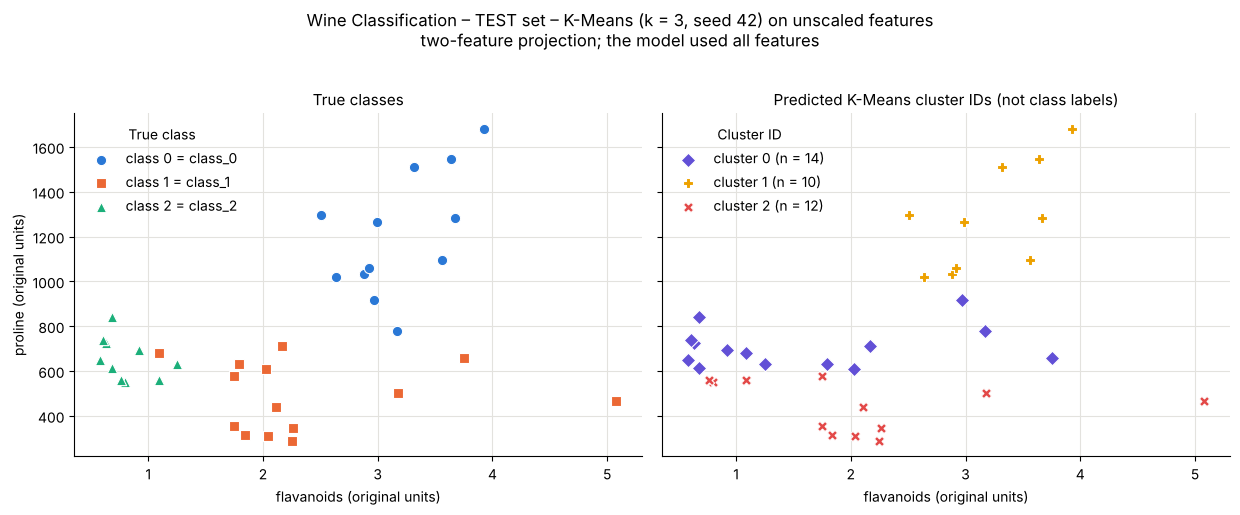

Saved figure: figures/wine_kmeans_test_unscaled.png


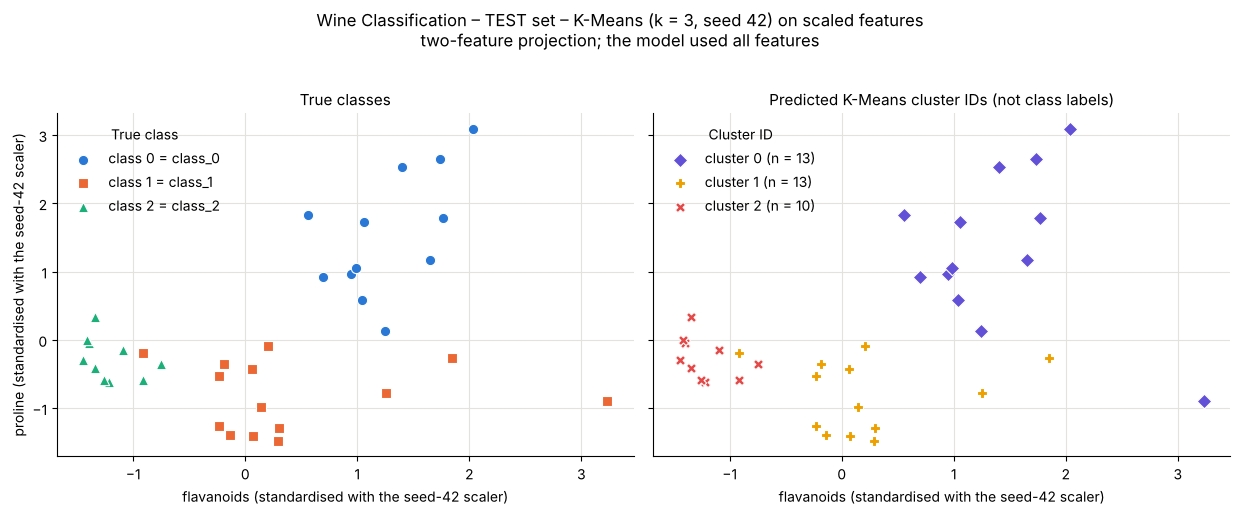

Saved figure: figures/wine_kmeans_test_scaled.png


In [45]:
def plot_classes_vs_clusters(representation):
    X_te = test_representations[representation]
    clusters = test_clusters[representation]
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5), sharex=True, sharey=True)

    for c, name, color, marker in zip(CLASS_LABELS, TARGET_NAMES, CLASS_COLORS, CLASS_MARKERS):
        mask = (y_test == c).values
        axes[0].scatter(X_te.loc[mask, feature_a], X_te.loc[mask, feature_b], s=55, color=color,
                        marker=marker, edgecolor="white", linewidth=0.8, label=f"class {c} = {name}")
    axes[0].set_title("True classes")
    axes[0].legend(frameon=False, title="True class")

    for k, color, marker in zip(range(N_CLUSTERS), CLUSTER_COLORS, CLUSTER_MARKERS):
        mask = clusters == k
        axes[1].scatter(X_te.loc[mask, feature_a], X_te.loc[mask, feature_b], s=55, color=color,
                        marker=marker, edgecolor="white", linewidth=0.8,
                        label=f"cluster {k} (n = {int(mask.sum())})")
    axes[1].set_title("Predicted K-Means cluster IDs (not class labels)")
    axes[1].legend(frameon=False, title="Cluster ID")

    unit = "original units" if representation == "unscaled" else "standardised with the seed-42 scaler"
    for ax in axes:
        ax.set_xlabel(f"{feature_a} ({unit})")
    axes[0].set_ylabel(f"{feature_b} ({unit})")
    fig.suptitle(f"{DATASET_TITLE} – TEST set – K-Means (k = {N_CLUSTERS}, seed 42) on {representation} features\n"
                 "two-feature projection; the model used all features", y=1.02)
    fig.tight_layout()
    save_fig(fig, f"kmeans_test_{representation}")

for representation in REPRESENTATIONS:
    plot_classes_vs_clusters(representation)

**Chosen features (from the seed-42 training data):** `flavanoids` (x-axis) and `proline` (y-axis).

**Classes versus clusters.** In the true-class panels, class_0 has high `proline` and high `flavanoids`, class_2 has low `flavanoids`, and class_1 has low `proline` with medium `flavanoids`. With **unscaled** features the three clusters are almost horizontal bands: one with `proline` above about 1000, one between about 600 and 900 and one below about 600. K-Means is effectively clustering on `proline` alone, so class_1 and class_2, which differ mainly in `flavanoids` and other small-scale features, are mixed. With **scaled** features the cluster panel is almost the same picture as the class panel. The one wine that is grouped differently is the class_1 point with a very high `flavanoids` value (about 3.2 standard deviations above the training mean), which is placed in the cluster of the class_0 wines.

The model used all 13 features; these plots are only a two-feature projection, so points that look close here can be far apart in the full space.

**Effect of scaling.** Scaling changes the partition completely, not only its score. The silhouette is higher for the unscaled model (0.493 vs 0.271) although its agreement with the classes is far lower (ARI 0.373 vs 0.909). Silhouette depends on the feature space, so this difference alone is not proof of a better or worse model.

**Information available during fitting.** K-Means received only the training feature matrix and the number of clusters. It never received `y_train`; it only minimises the squared distances of the points to their cluster centres, and its cluster IDs are arbitrary. The three classifiers received both the features and the labels, so they could learn which features and which values separate the three cultivars. For K-Means the labels were used only after fitting, to calculate ARI and the contingency tables.

## Export: results for the shared CSV files and run inventory

The six CSV files combine both datasets and contain a `dataset` column. Each notebook replaces **only its own dataset's rows** in every file, so the two notebooks can be run in any order and re-running one never duplicates rows.

In [46]:
DATASET_ORDER = ["breast_cancer", "wine"]

def save_combined(df, filename):
    """Write this dataset's rows into a shared CSV file (rows of the other dataset are kept)."""
    path = RESULTS_DIR / filename
    if path.exists():
        old = pd.read_csv(path, float_precision="round_trip")   # exact values, independent of run order
        old = old[old["dataset"] != DATASET_KEY]
        combined = pd.concat([old, df], ignore_index=True) if len(old) else df.copy()
    else:
        combined = df.copy()
    combined["_order"] = combined["dataset"].map({k: i for i, k in enumerate(DATASET_ORDER)})
    combined = combined.sort_values("_order", kind="stable").drop(columns="_order")
    combined.to_csv(path, index=False)
    return len(df), len(combined)

exports = {
    "classifier_runs.csv": runs_df,
    "classifier_summary.csv": summary,
    "classifier_test.csv": classifier_test,
    "kmeans_runs.csv": kmeans_runs,
    "kmeans_summary.csv": kmeans_summary,
    "kmeans_test.csv": kmeans_test,
}
required_per_dataset = {"classifier_runs.csv": 66, "classifier_summary.csv": 22, "classifier_test.csv": 1,
                        "kmeans_runs.csv": 6, "kmeans_summary.csv": 2, "kmeans_test.csv": 2}
export_rows = []
for filename, df in exports.items():
    n_here, n_total = save_combined(df, filename)
    assert n_here == required_per_dataset[filename]
    export_rows.append({"csv_file": f"results/{filename}", "rows from this dataset": n_here,
                        "required per dataset": required_per_dataset[filename],
                        "rows in file now (both datasets when complete)": n_total})
print(f"[{DATASET_TITLE}] Rows written to the six shared CSV files")
display(pd.DataFrame(export_rows))

[Wine Classification] Rows written to the six shared CSV files


,csv_file,rows from this dataset,required per dataset,rows in file now (both datasets when complete)
0,results/classifier_runs.csv,66,66,132
1,results/classifier_summary.csv,22,22,44
2,results/classifier_test.csv,1,1,2
3,results/kmeans_runs.csv,6,6,12
4,results/kmeans_summary.csv,2,2,4
5,results/kmeans_test.csv,2,2,4


In [47]:
# Run inventory for this dataset
n_classifier_fits = len(runs_df)
n_kmeans_fits = len(kmeans_runs)
print(f"[{DATASET_TITLE}] classifier fits: {n_classifier_fits}  +  K-Means fits: {n_kmeans_fits}  "
      f"=  {n_classifier_fits + n_kmeans_fits} model fits for this dataset")
print("Test evaluations reuse seed-42 fitted models (1 classifier + 2 clusterings) and add no fits.")
assert n_classifier_fits == 66 and n_kmeans_fits == 6

figure_files = sorted(p.name for p in FIG_DIR.glob(f"{DATASET_KEY}_*.png"))
print(f"\nFigure files written by this notebook: {len(figure_files)}")
for name in figure_files:
    print("  figures/" + name)

[Wine Classification] classifier fits: 66  +  K-Means fits: 6  =  72 model fits for this dataset
Test evaluations reuse seed-42 fitted models (1 classifier + 2 clusterings) and add no fits.

Figure files written by this notebook: 10
  figures/wine_boxplots_first_seven.png
  figures/wine_boxplots_last_six.png
  figures/wine_class_distribution.png
  figures/wine_correlation_heatmap.png
  figures/wine_kmeans_test_scaled.png
  figures/wine_kmeans_test_unscaled.png
  figures/wine_knn_neighbors_comparison.png
  figures/wine_test_confusion_matrix.png
  figures/wine_test_roc_curves.png
  figures/wine_tree_depth_comparison.png


### Combined final tables (both datasets)

The two-row final classifier test table and the four-row final K-Means test table, read back from the shared CSV files. They are complete once both notebooks have been run.

In [48]:
combined_clf_test = pd.read_csv(RESULTS_DIR / "classifier_test.csv")
combined_km_test = pd.read_csv(RESULTS_DIR / "kmeans_test.csv")

print(f"Final classifier TEST table – seed-42 selected model of each dataset "
      f"({len(combined_clf_test)} of 2 rows present: {list(combined_clf_test['dataset'])})")
display(combined_clf_test)

print(f"Final K-Means TEST table – seed 42, both representations of each dataset "
      f"({len(combined_km_test)} of 4 rows present)")
with pd.option_context("display.max_colwidth", None):
    display(combined_km_test)

if len(combined_clf_test) < 2 or len(combined_km_test) < 4:
    print("Run the companion notebook (breast_cancer.ipynb) to add the rows of the other dataset.")

Final classifier TEST table – seed-42 selected model of each dataset (2 of 2 rows present: ['breast_cancer', 'wine'])


,dataset,selected_config,evaluation_seed,val_macro_f1_mean,val_macro_f1_std,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc
0,breast_cancer,breast_cancer_knn_scaled_k7,42,0.9677,0.0297,0.9737,0.98,0.9643,0.9713,0.9888
1,wine,wine_knn_scaled_k11,42,0.9814,0.0323,1.0000,1.00,1.0000,1.0000,1.0000


Final K-Means TEST table – seed 42, both representations of each dataset (4 of 4 rows present)


,dataset,representation,seed,n_clusters,n_test_samples,test_cluster_counts,test_distinct_clusters,test_ari,test_silhouette
0,breast_cancer,unscaled,42,2,114,cluster 0: 86; cluster 1: 28,2,0.5585,0.7120
1,breast_cancer,scaled,42,2,114,cluster 0: 74; cluster 1: 40,2,0.7354,0.3251
2,wine,unscaled,42,3,36,cluster 0: 14; cluster 1: 10; cluster 2: 12,3,0.3733,0.4929
3,wine,scaled,42,3,36,cluster 0: 13; cluster 1: 13; cluster 2: 10,3,0.9088,0.2711
